# Pipeline Responsible AI — Link Prediction sur Pokec

**Auteurs :**
- Amir Kashani
- Mehdi Ait Hamma
- Tahiana Hajanirina Andriambahoaka
- Younes Boutrouft


**Objectif** : Construire un pipeline complet de Responsible AI sur un graphe social (Pokec, région Ceska republika), en suivant une approche scientifique en 4 actes :

> **Observer** → **Diagnostiquer** → **Corriger** → **Valider**

**Tâche** : Prédiction de liens (link prediction) — prédire si deux utilisateurs sont amis à partir de leurs attributs et de la structure du graphe.

**Attribut sensible** : Genre (0=F, 1=H). Le graphe présente une forte hétérophilie de genre (ratio H→F / H→H ).

**Architecture** : GCN Encoder (2 couches, 128→64) + Décodeur dot-product + sigmoïde.

---

| Acte | Question | Méthode |
|------|----------|---------|
| 1 | Le modèle est-il biaisé ? | Baseline + métriques fairness |
| 2 | D'où vient le biais ? | GNNExplainer + ablation |
| 3 | Comment le corriger ? | Reweighting, DP reg., FairGNN |
| 4 | La correction tient-elle ? | MC Dropout, perturbations, ECE |

**Mention** : 
Nous avons utilisé CLAUDE pour l'implémentation de la pipeline, en adaptant les méthodes à notre cas d'étude sur Pokec. Les analyses et les conclusions restent notre propre travail.

## 0. Configuration et chargement des données

In [ ]:
# Install dependencies
!pip install -r requirements.txt

In [1]:
import warnings; warnings.filterwarnings('ignore')
import sys, os
import gc
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch
from torch_geometric.transforms import RandomLinkSplit
from copy import deepcopy

# Ajouter le dossier au path Python
_nb_file = globals().get('__vsc_ipynb_file__')
_nb = None
if _nb_file:
    _candidate = Path(str(_nb_file)).resolve().parent
    if _candidate.exists():   # False sur le serveur distant → fallback
        _nb = _candidate
if _nb is None:
    _nb = next(
        (p for p in [Path.cwd(), *Path.cwd().parents]
         if (p / 'utils.py').exists()),
        Path.cwd()
    )
if str(_nb) not in sys.path:
    sys.path.insert(0, str(_nb))
os.chdir(_nb)

# Modules du projet
from utils import *
from models import *
from metrics import *
from visualisation import *



# activer le rechargement automatique des modules
%load_ext autoreload
%autoreload 2

# Configuration globale
set_seed(42)
set_academic_style()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_DIR = '../data' if Path('../data').exists() else 'data'
print(f"Device : {device} | Données : {DATA_DIR}")
print(f"CWD : {Path.cwd()}")

# region : None pour tout le dataset (pas de split régional)
REGION='ceska republika'

Device : cuda | Données : ../data
CWD : /home/infres/boutrouft-25/projects/IADATA-708/IA-DATA708/notebooks


A exécuter si besoin de vérifier la mémoire GPU disponible !

In [ ]:
# Si besoin 
print(torch.cuda.memory_allocated() / 1e9, "GB allocated")
print(torch.cuda.memory_reserved() / 1e9, "GB reserved")

0.0 GB allocated
0.0 GB reserved


A exécuter si besoin de libérer la mémoire GPU.

In [ ]:
# Si besoin de libérer de la mémoire GPU
gc.collect()
torch.cuda.empty_cache()

print(torch.cuda.memory_allocated() / 1e9, "GB allocated")
print(torch.cuda.memory_reserved() / 1e9, "GB reserved")

In [3]:
# télécharger les données si elles n'existent pas déjà
print("Téléchargement des données Pokec...")
download_pokec(DATA_DIR)

Téléchargement des données Pokec...
soc-pokec-relationships.txt.gz déjà présent, skipping download.
soc-pokec-profiles.txt.gz déjà présent, skipping download.


In [4]:
# Chargement du graphe Pokec — sous-ensemble Ceska republika (région la plus biaisée)
data, sens, profiles = load_pokec(DATA_DIR, region=REGION)
print(f"Graphe : {data.num_nodes:,} noeuds | {data.edge_index.shape[1]:,} arêtes | {data.x.shape[1]} features")
print(f"Genre  : F={(sens==0).sum().item():,} | H={(sens==1).sum().item():,} | ratio H/F={(sens==1).sum()/(sens==0).sum():.2f}")

Graphe : 31,298 noeuds | 107,802 arêtes | 64 features
Genre  : F=17,835 | H=13,463 | ratio H/F=0.75


In [5]:
# Split des arêtes : Train 70% / Val 15% / Test 15%
# Le GCN ne voit QUE les arêtes train dans edge_index (pas de fuite de données)
set_seed(42)
train_data, val_data, test_data = RandomLinkSplit(
    num_val=0.15, num_test=0.15, is_undirected=True, add_negative_train_samples=True
)(data)
print(f"Train : {train_data.edge_label.shape[0]:,} paires")
print(f"Val   : {val_data.edge_label.shape[0]:,} paires")
print(f"Test  : {test_data.edge_label.shape[0]:,} paires")

Train : 75,462 paires
Val   : 16,170 paires
Test  : 16,170 paires


---

## 1 - Acte 1 — Baseline : le modèle est-il biaisé ?

On entraîne 3 architectures GNN (GCN, SGC, GAT) et on mesure performance + fairness pour identifier le modèle de référence.

| Hyperparamètre | Valeur |
|---|---|
| Hidden dim | 128 → 64 |
| Dropout | 0.5 |
| Epochs | 100 |
| Learning rate | 0.01 (GCN, SGC) / 0.005 (GAT) |
| Weight decay | 5e-4 |
| Seed | 42 |

#### 1.1 - Entraînement des 3 modèles

In [6]:
# Entraînement des 3 modèles
set_seed(42)
model_gcn = GCN(data.x.shape[1]).to(device)
best_auc_gcn = train_with_best(model_gcn, train_data, val_data, device, epochs=100, lr=0.01)
print(f"GCN — Best Val AUC : {best_auc_gcn:.4f}")

set_seed(42)
model_sgc = SGC(data.x.shape[1]).to(device)
best_auc_sgc = train_with_best(model_sgc, train_data, val_data, device, epochs=100, lr=0.01)
print(f"SGC — Best Val AUC : {best_auc_sgc:.4f}")

set_seed(42)
model_gat = GAT(data.x.shape[1], hid=128, out=64, heads=4, drop=0.5).to(device)
best_auc_gat = train_with_best(model_gat, train_data, val_data, device, epochs=100, lr=0.005)
print(f"GAT — Best Val AUC : {best_auc_gat:.4f}")

Entraînement:   0%|          | 0/100 [00:00<?, ?it/s]

GCN — Best Val AUC : 0.8328


Entraînement:   0%|          | 0/100 [00:00<?, ?it/s]

SGC — Best Val AUC : 0.7665


Entraînement:   0%|          | 0/100 [00:00<?, ?it/s]

GAT — Best Val AUC : 0.8324


#### 1.2 - Évaluation : performance + fairness + leakage

In [7]:
# Évaluation systématique : performance + fairness + leakage
results = {}
for name, mdl in [('GCN', model_gcn), ('SGC', model_sgc), ('GAT', model_gat)]:
    tp, tl, tpt, auc, ap, f, f1_global = evaluate_link_pred(mdl, test_data, sens, device)
    mdl.eval()
    with torch.no_grad():
        z = mdl.encode(test_data.x.to(device), test_data.edge_index.to(device)).cpu()
    cos_fh, gen_acc_tr, gen_acc_te, prop_majo = probe_gender(z, sens)
    data_v, pred_v, diffs = pair_distribution(tp, tl, tpt)
    results[name] = {
        'tp': tp, 'tl': tl, 'tpt': tpt,
        'auc': auc, 'ap': ap, 'f': f, 'f1': f1_global,
        'cos_fh': cos_fh, 'acc_tr': gen_acc_tr, 'acc_te': gen_acc_te,
        'prop_majo': prop_majo, 'leakage': gen_acc_te - prop_majo,
        'data_v': data_v, 'pred_v': pred_v, 'diffs': diffs,
    }

In [8]:
# Tableau comparatif des 3 modèles
pd.DataFrame({name: {
    'AUC': r['auc'], 'AP': r['ap'], 'F1': r['f1'],
    'DP gap': r['f']['DP'], 'EOpp': r['f']['EOpp'], 'EO': r['f']['EO'],
    'DI': r['f']['DI'], 'Cosine F/H': r['cos_fh'],
    'Leakage': f"{100*r['leakage']:+.1f} pp",
} for name, r in results.items()}).T

,AUC,AP,F1,DP gap,EOpp,EO,DI,Cosine F/H,Leakage
GCN,0.855609,0.872567,0.746882,0.050994,0.020352,0.048862,0.93077,0.666094,+25.1 pp
SGC,0.771399,0.719737,0.735372,0.011607,0.062678,0.124149,0.983426,-0.177934,+30.4 pp
GAT,0.848151,0.8566,0.74839,0.049841,0.019561,0.053323,0.931849,0.972669,+21.0 pp


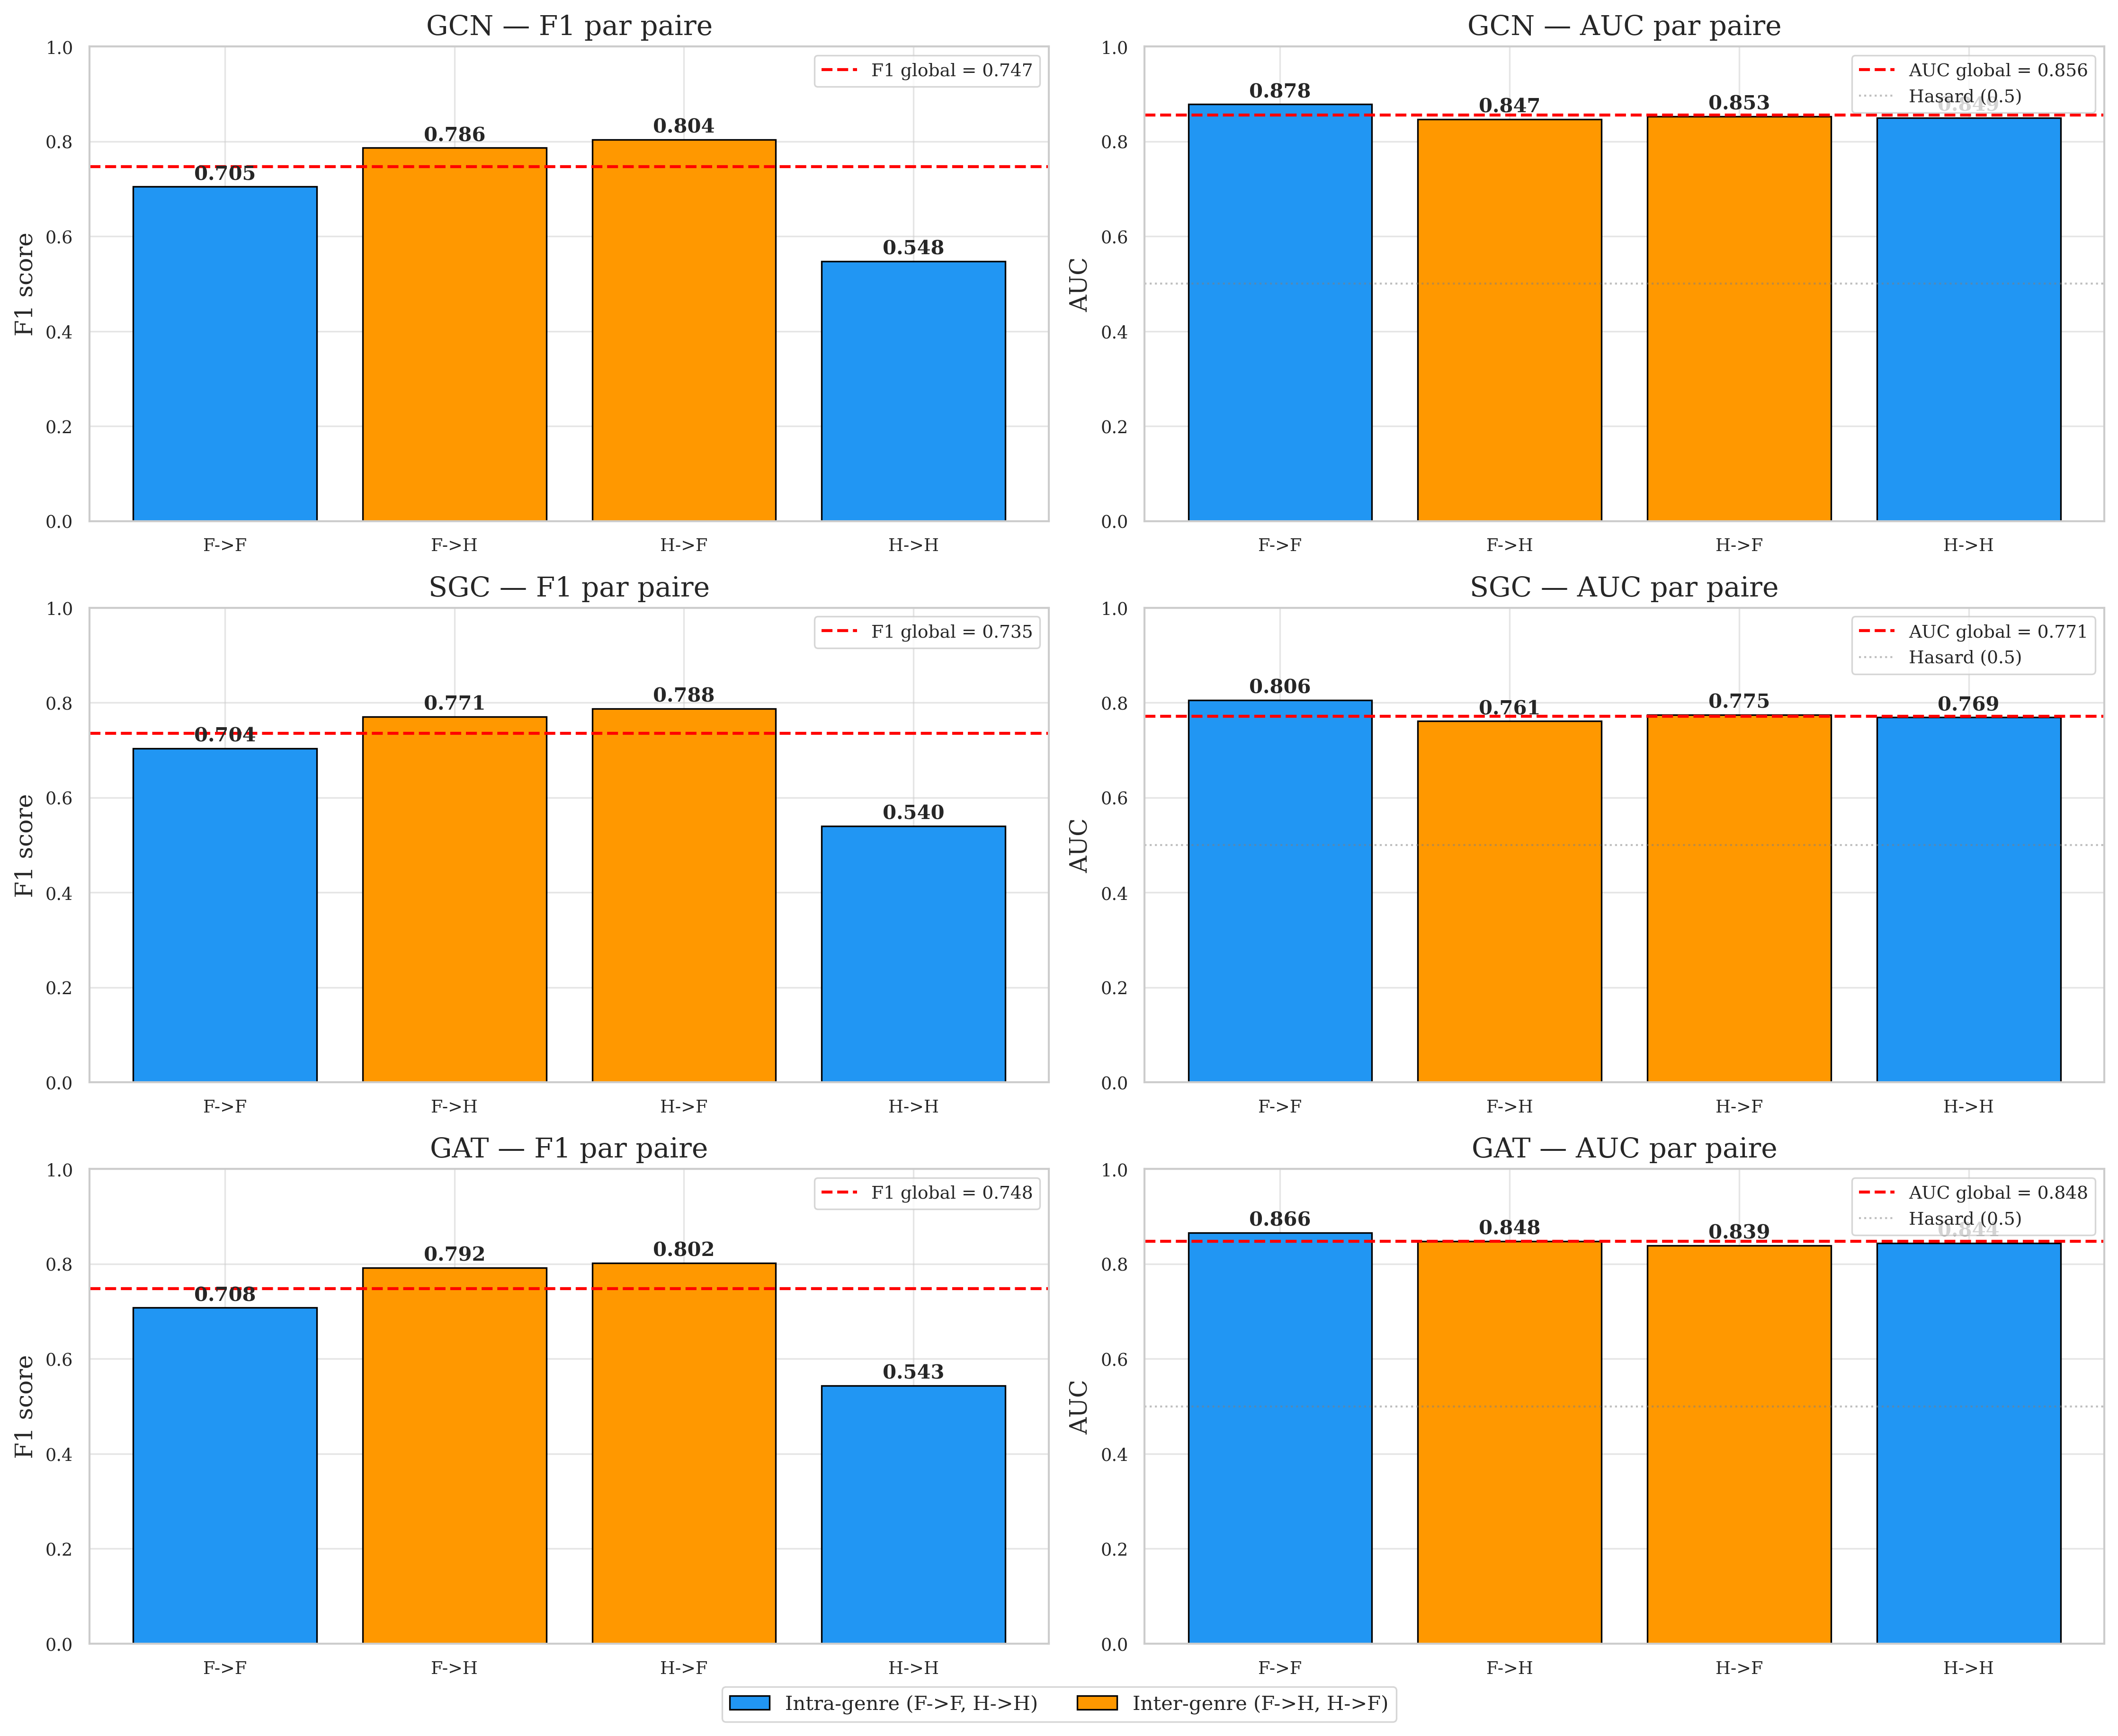

In [9]:
# Performance par type de paire (F1 et AUC)
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for i, name in enumerate(['GCN', 'SGC', 'GAT']):
    r = results[name]
    bar_per_pair(axes[i, 0], r['f']['pf1'], f'{name} — F1 par paire', 'F1 score',
                 hline=r['f1'], hline_label=f"F1 global = {r['f1']:.3f}")
    bar_per_pair(axes[i, 1], r['f']['pa'], f'{name} — AUC par paire', 'AUC',
                 hline=r['auc'], hline_label=f"AUC global = {r['auc']:.3f}",
                 extras=[(0.5, 'Hasard (0.5)', {'alpha': 0.5})])
fairness_legend(fig)
plt.tight_layout()
plt.show()

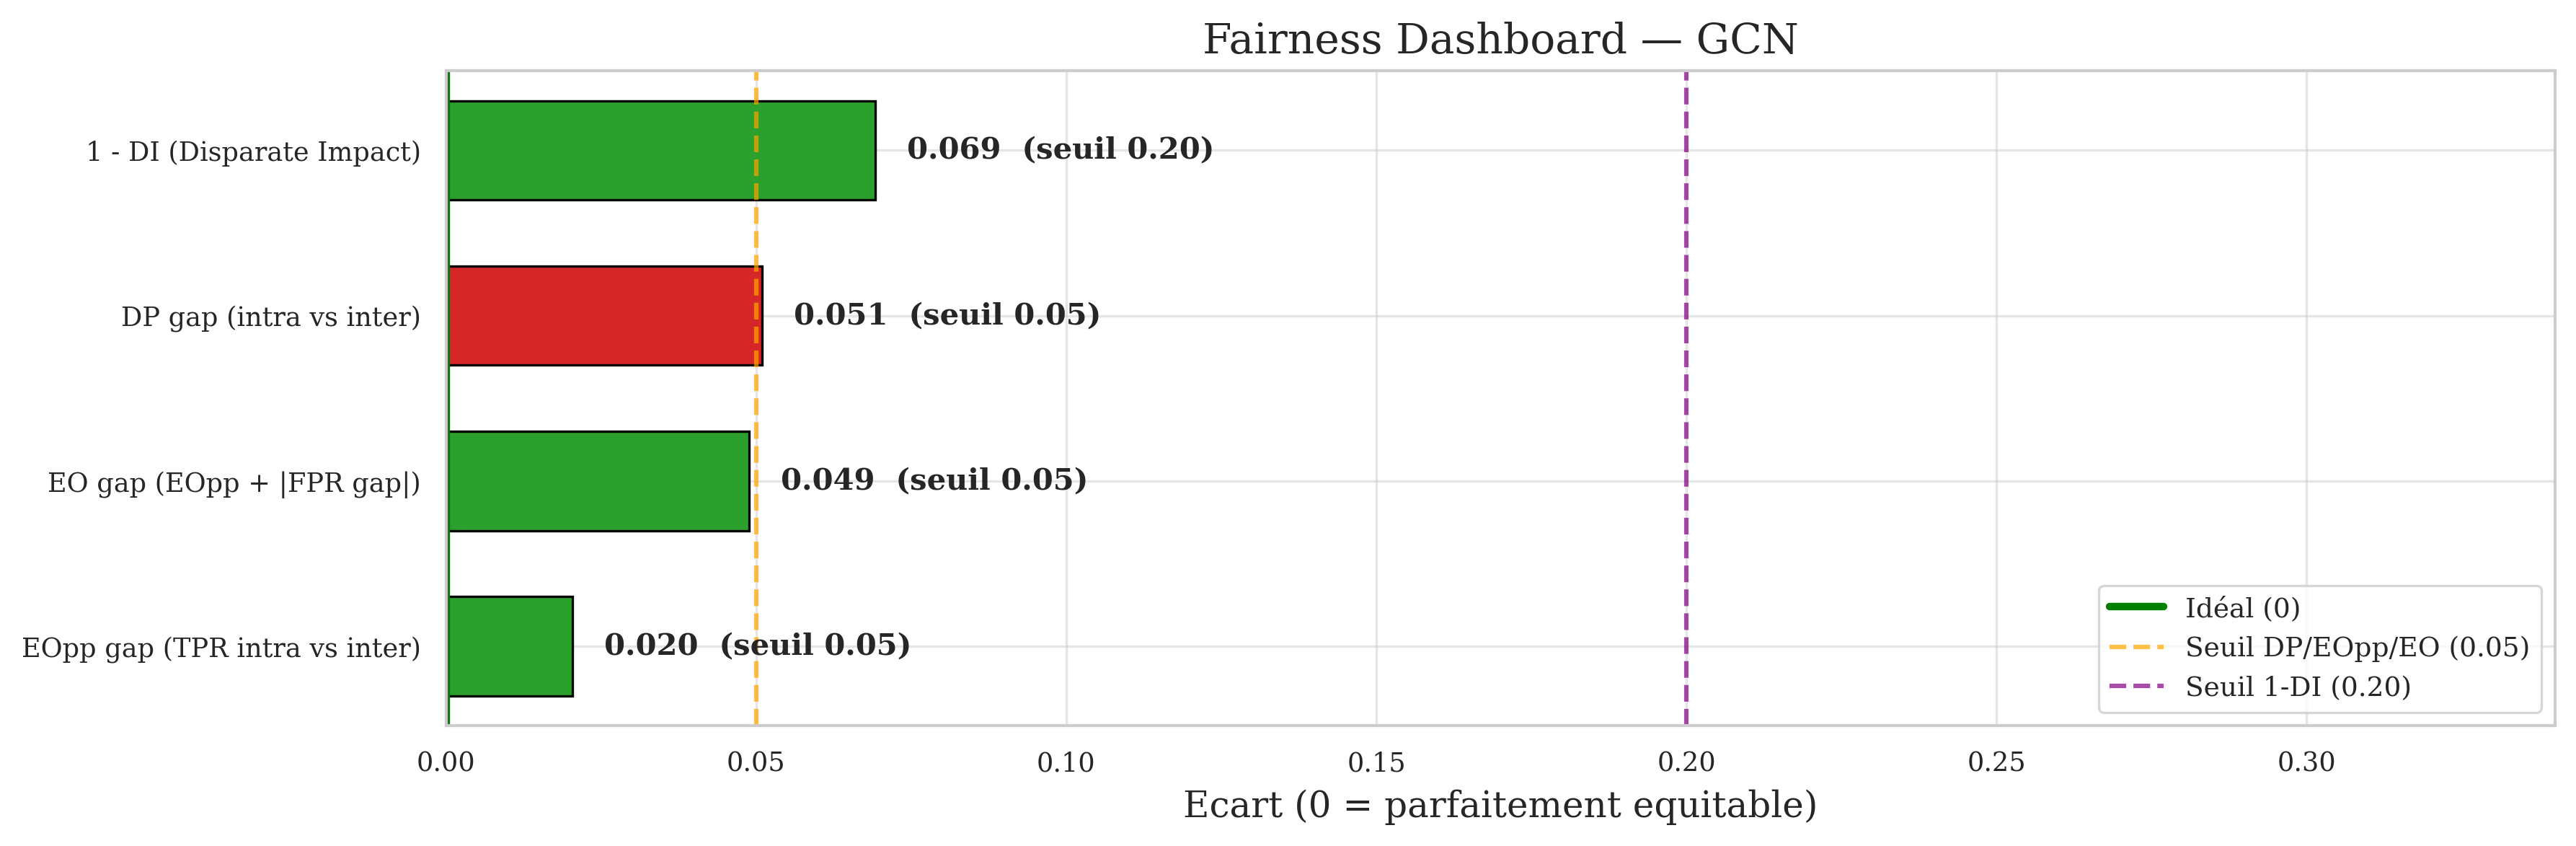

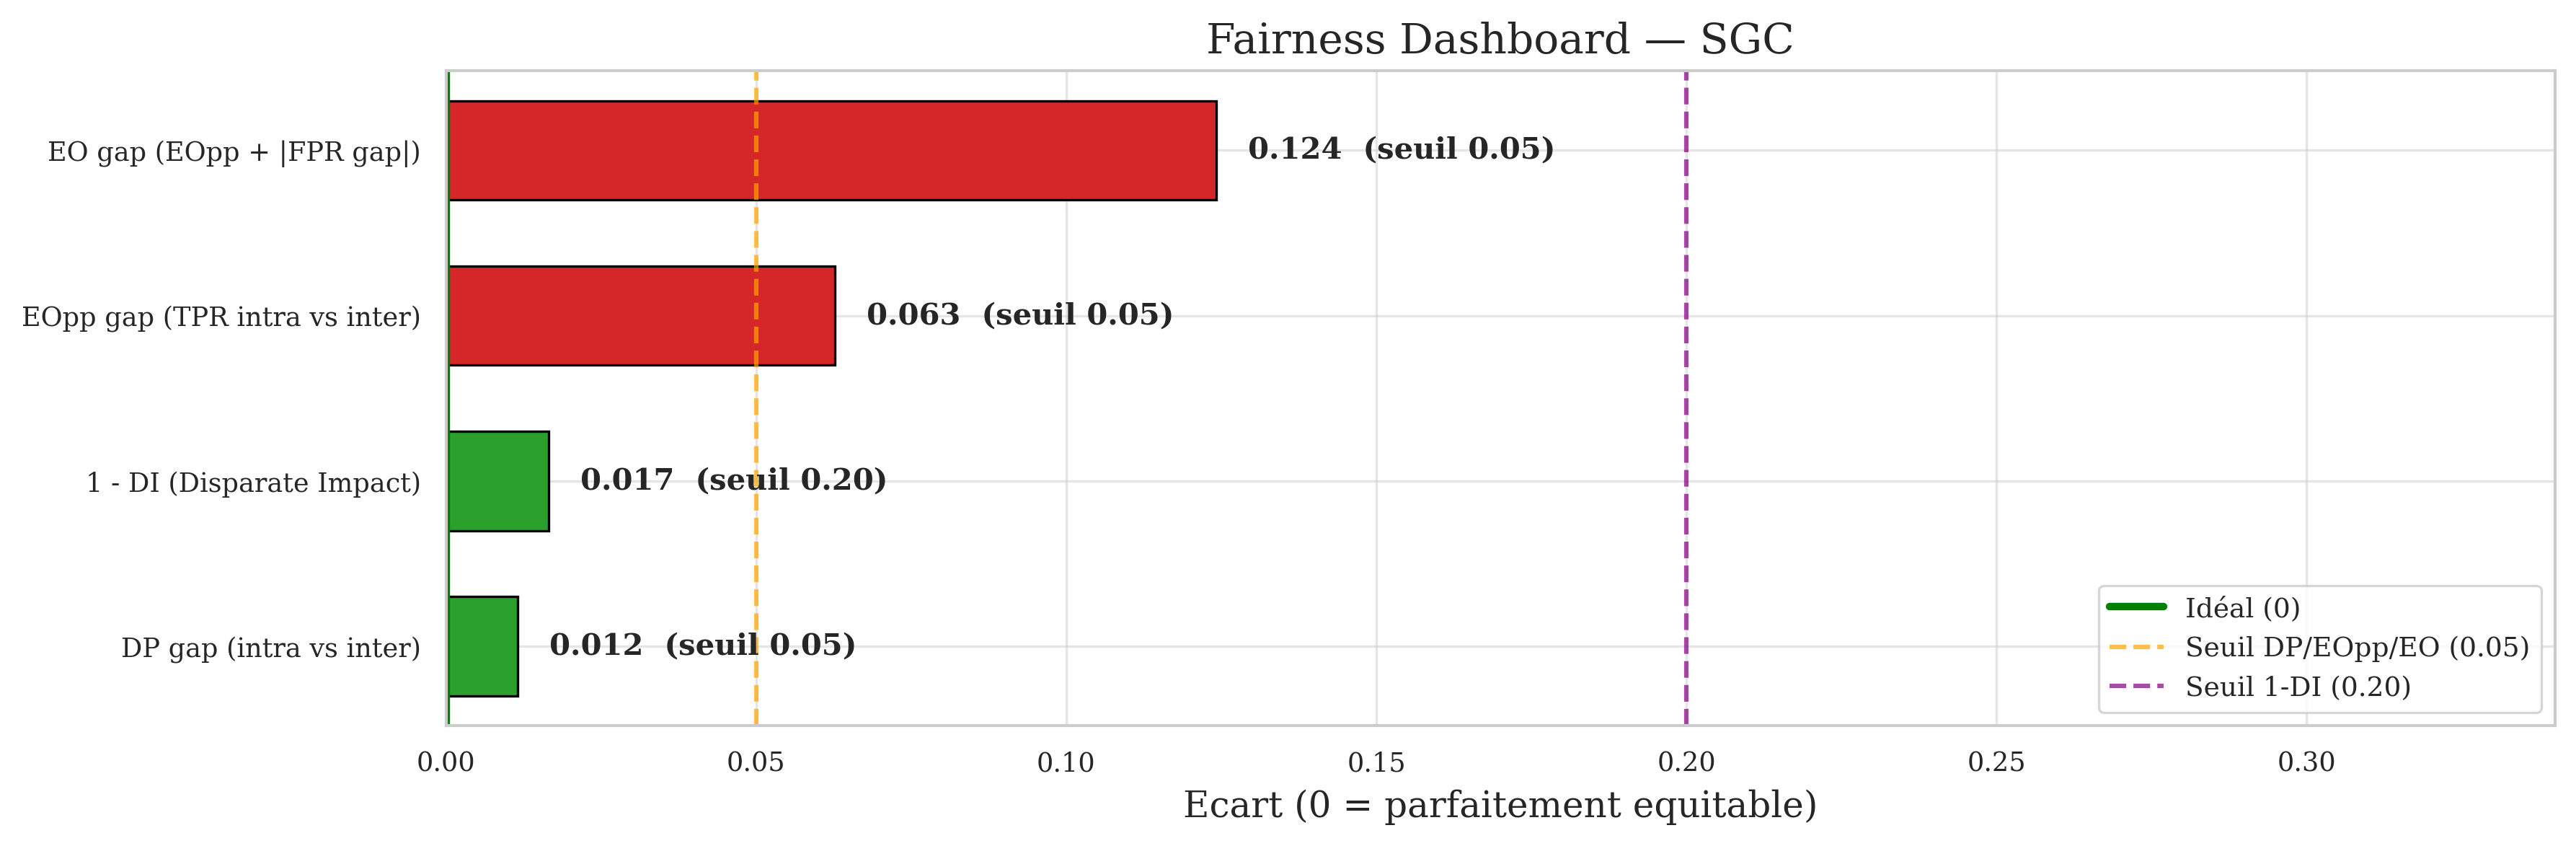

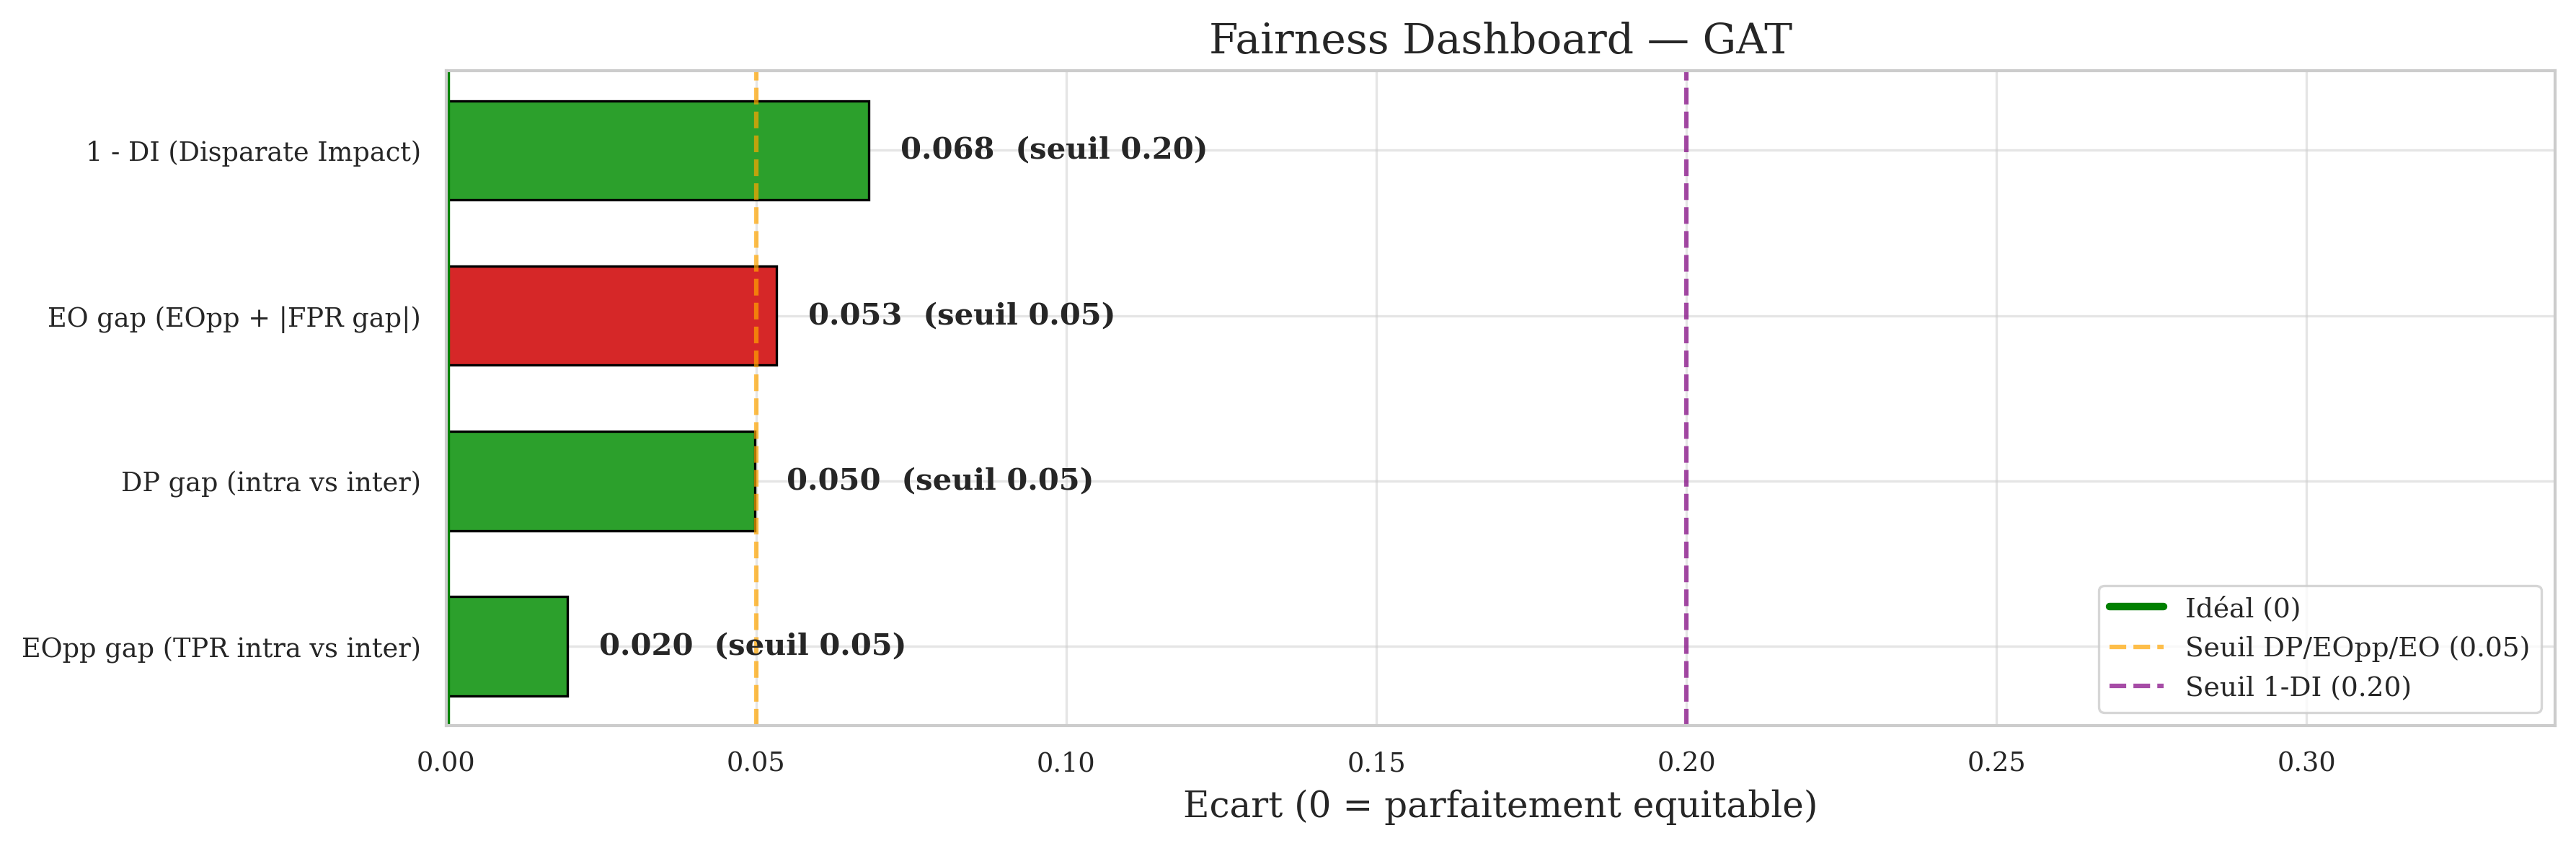

In [10]:
# Fairness dashboards
for name in ['GCN', 'SGC', 'GAT']:
    f = results[name]['f']
    metrics = [
        ('DP gap (intra vs inter)',       f['DP'],     0.05),
        ('EOpp gap (TPR intra vs inter)', f['EOpp'],   0.05),
        ('EO gap (EOpp + |FPR gap|)',     f['EO'],     0.05),
        ('1 - DI (Disparate Impact)',     1 - f['DI'], 0.20),
    ]
    barh_dashboard(metrics, title=f'Fairness Dashboard — {name}',
                   xlabel='Ecart (0 = parfaitement equitable)',
                   threshold_lines=[(0.05, 'Seuil DP/EOpp/EO (0.05)', 'orange'),
                                    (0.20, 'Seuil 1-DI (0.20)', 'purple')])
    plt.tight_layout() 
    plt.show()

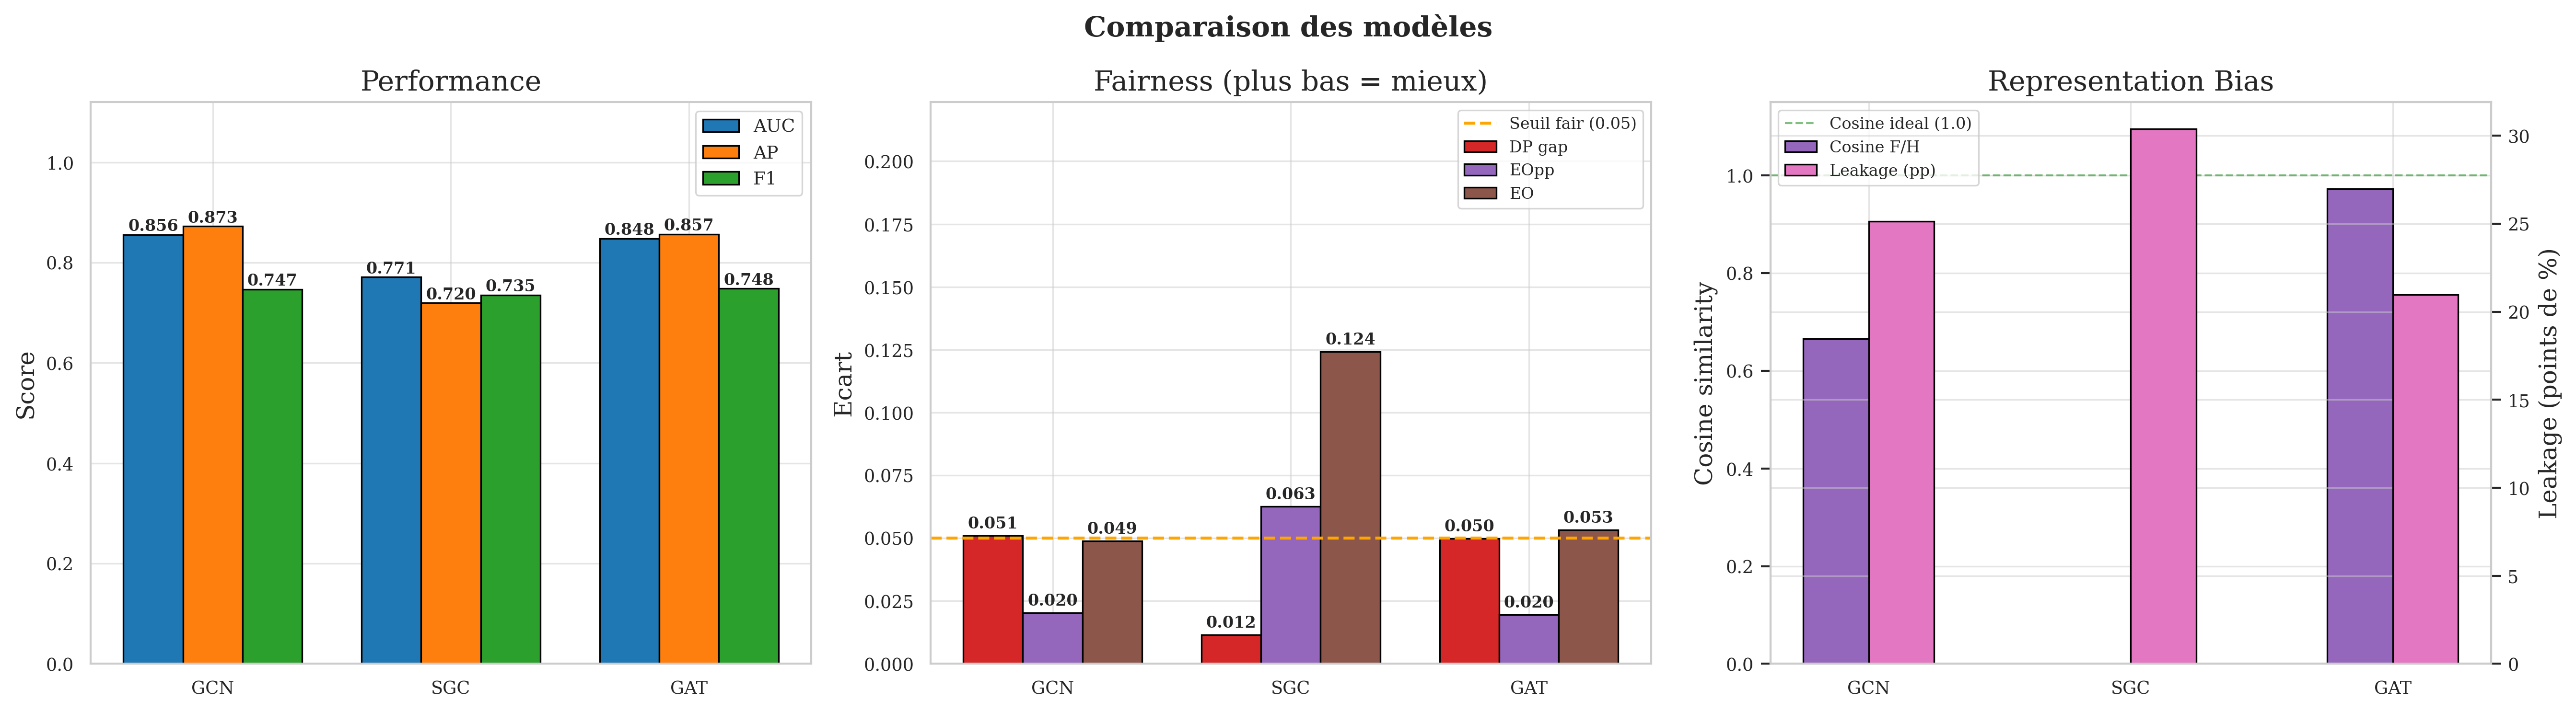

In [11]:
# Comparaison 3 panneaux : Performance / Fairness / Leakage
plot_models_comparison(results)

### Choix du modèle de référence : GCN

| Critère | GCN | SGC | GAT |
|---------|-----|-----|-----|
| AUC | **~0.856** | ~0.771 | ~0.848 |
| DP gap | 0.051 (borderline) | 0.012 | 0.051 |
| Cosine F/H | 0.667 | -0.178 | 0.972 |

**Justification** :
1. **Architecture de référence** en fairness GNN — résultats comparables à la littérature
2. **Profil de biais idéal** : cosine = 0.667 → séparation claire des genres, suffisante pour démontrer une correction
3. **Architecture simple** → tout changement sous régularisation est attribuable au compromis perf/fairness, sans facteur confondant

Le SGC est trop faible (AUC 0.771), le GAT est déjà quasi gender-neutral (cosine 0.972).

---

## 2- Acte 2 — Diagnostic XAI : d'où vient le biais ?

Trois approches complémentaires pour localiser l'origine du biais :
1. **GNNExplainer** : quelles features expliquent les prédictions de liens ?
2. **Attention GAT** : le modèle sur-pondère-t-il les voisins du même genre ?
3. **Ablation contrefactuelle** : le biais est-il dans la feature "genre" ou dans la topologie ?

#### 2.1 GNNExplainer — Importance des features par type de paire

On explique 48 arêtes test positives (12 par type de paire) avec GNNExplainer (200 epochs, lr=0.01). Pour chaque arête, on obtient un masque d'importance sur les 64 features d'entrée.

In [12]:
# GNNExplainer : 48 arêtes test (12 par type de paire), 200 epochs
feat_imp, explain_edges, explain_pt = run_gnnexplainer(model_gcn, test_data, sens, device, n_per_type=12)

48 arêtes : F->F=12 | F->H=12 | H->F=12 | H->H=12


GNNExplainer:   0%|          | 0/48 [00:00<?, ?it/s]

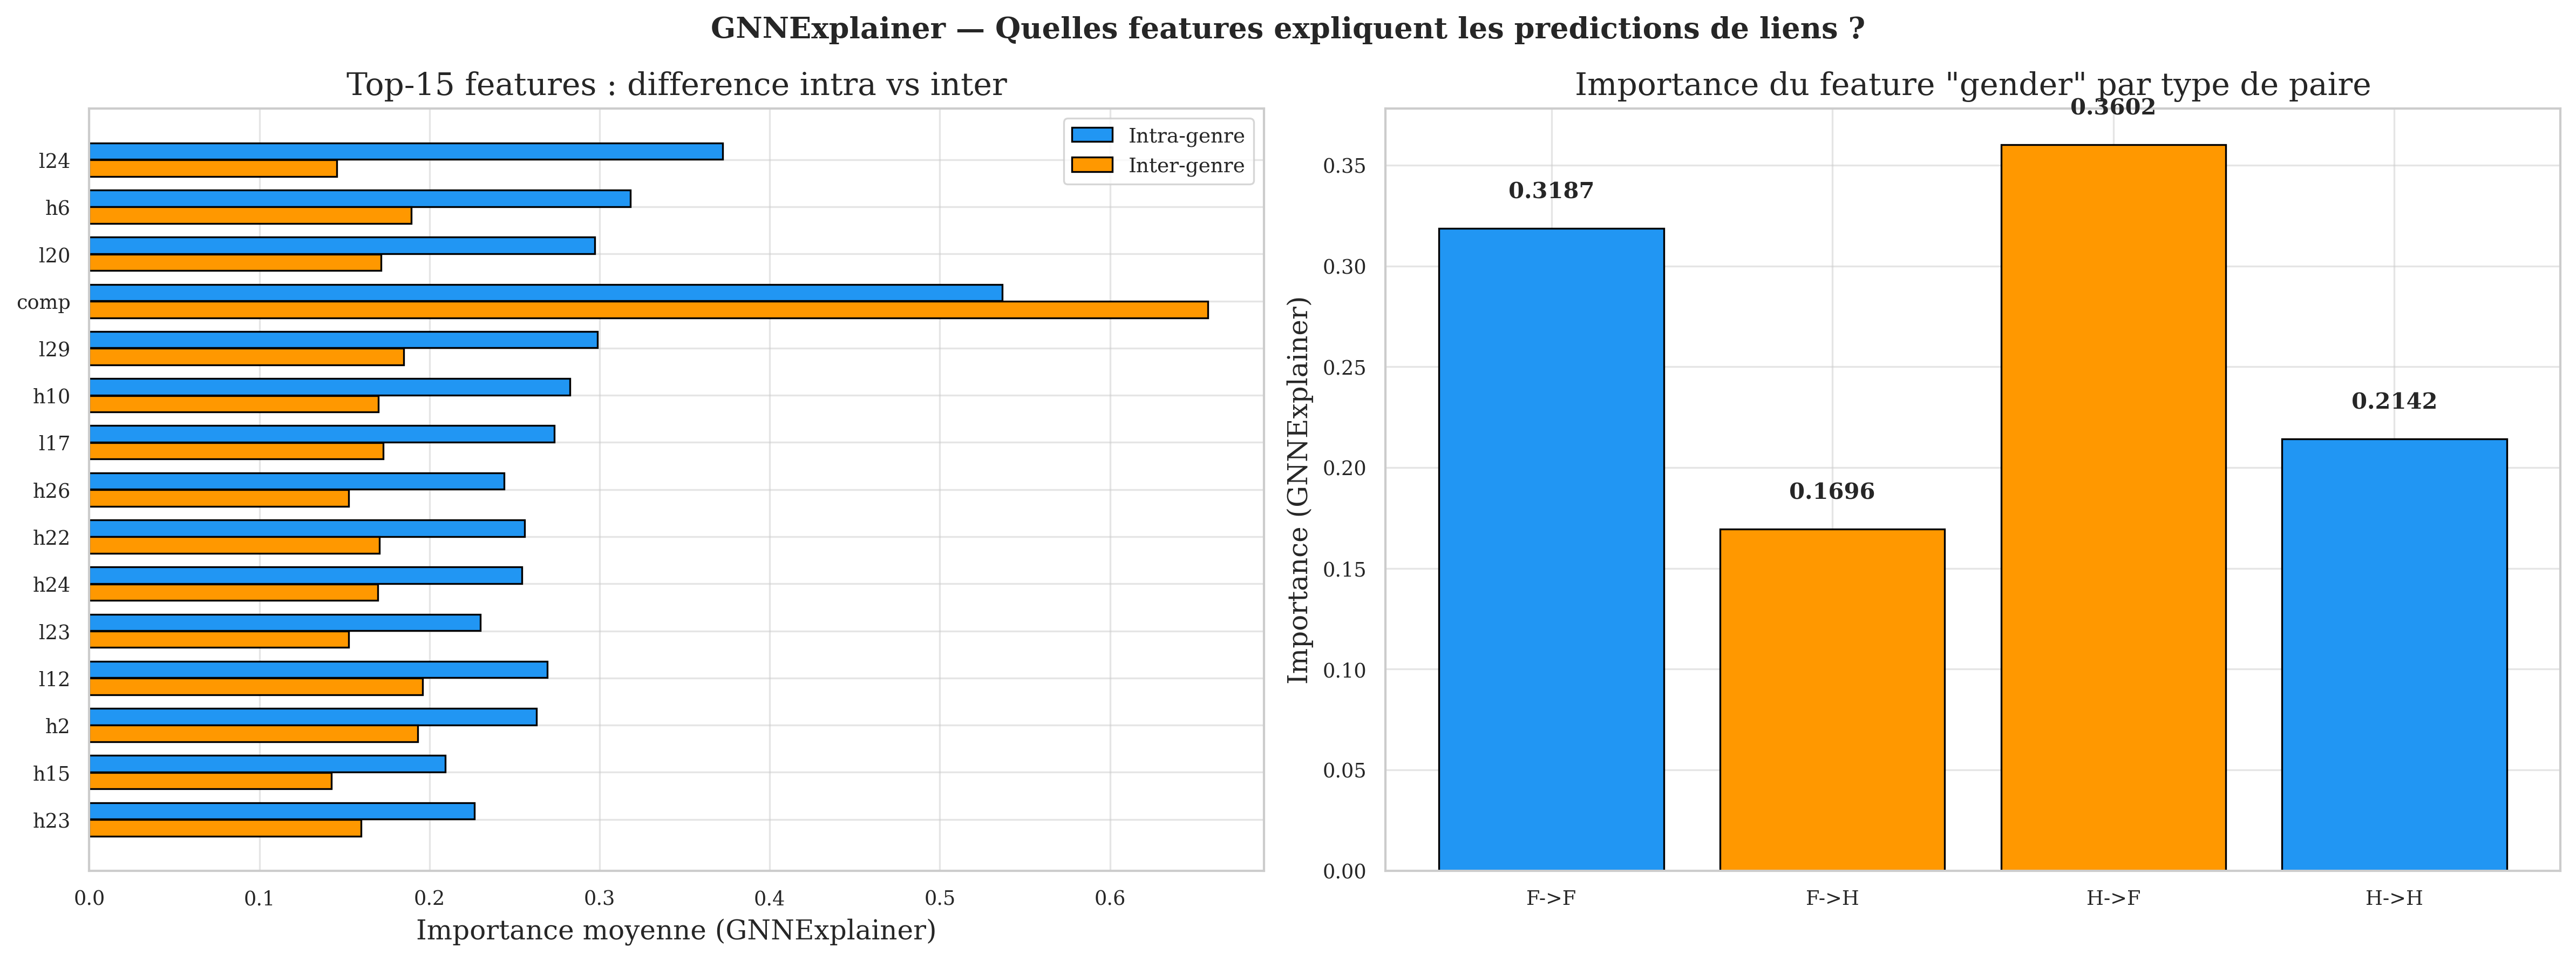

Feature 'gender' : rang 3/64 en importance globale


In [13]:
# Résultats GNNExplainer : top features + importance du genre
plot_feature_importance(feat_imp)

#### 2.2 Validation XAI — Fidelity+/-

On vérifie que les masques GNNExplainer sont fidèles au modèle :
- **Fidelity+** : masquer les K features les plus importants → la prédiction doit **chuter**
- **Fidelity-** : masquer les K features les moins importants → la prédiction doit **rester stable**

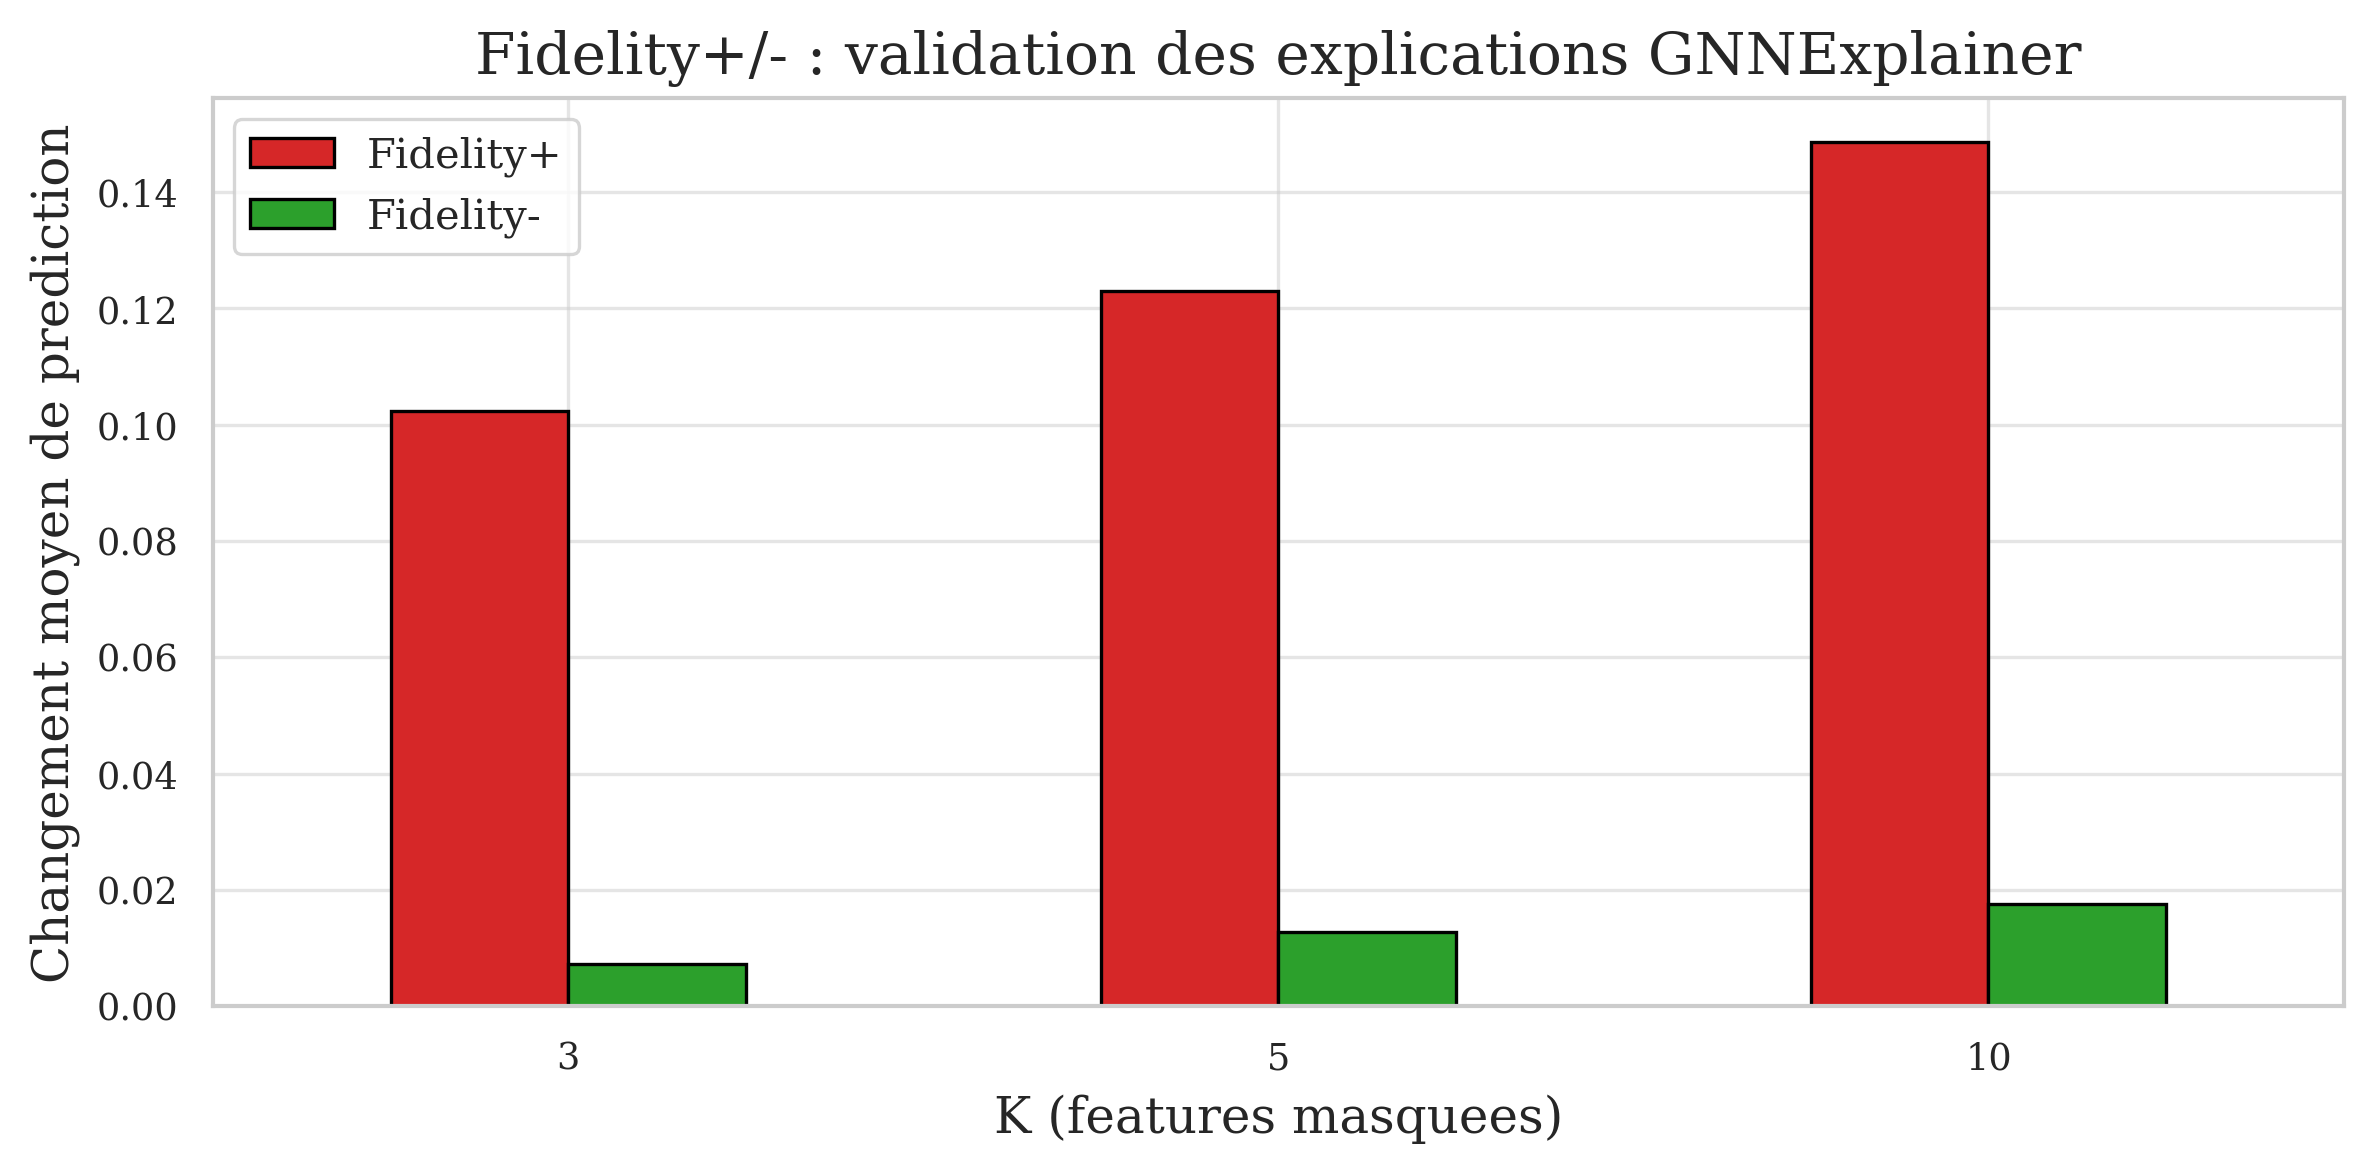

    Fidelity+  Fidelity-
K                       
3      0.1024     0.0072
5      0.1230     0.0127
10     0.1487     0.0176


In [14]:
# Fidelity+/- pour K = 3, 5, 10
df_fid = compute_fidelity(model_gcn, test_data, feat_imp, explain_edges, device, K_values=[3, 5, 10])
plot_fidelity(df_fid)

#### 2.3 Attention GAT — biais d'homophilie

Le GAT dispose d'un mécanisme d'attention natif. Question : **le modèle prête-t-il plus attention aux voisins du même genre ?**

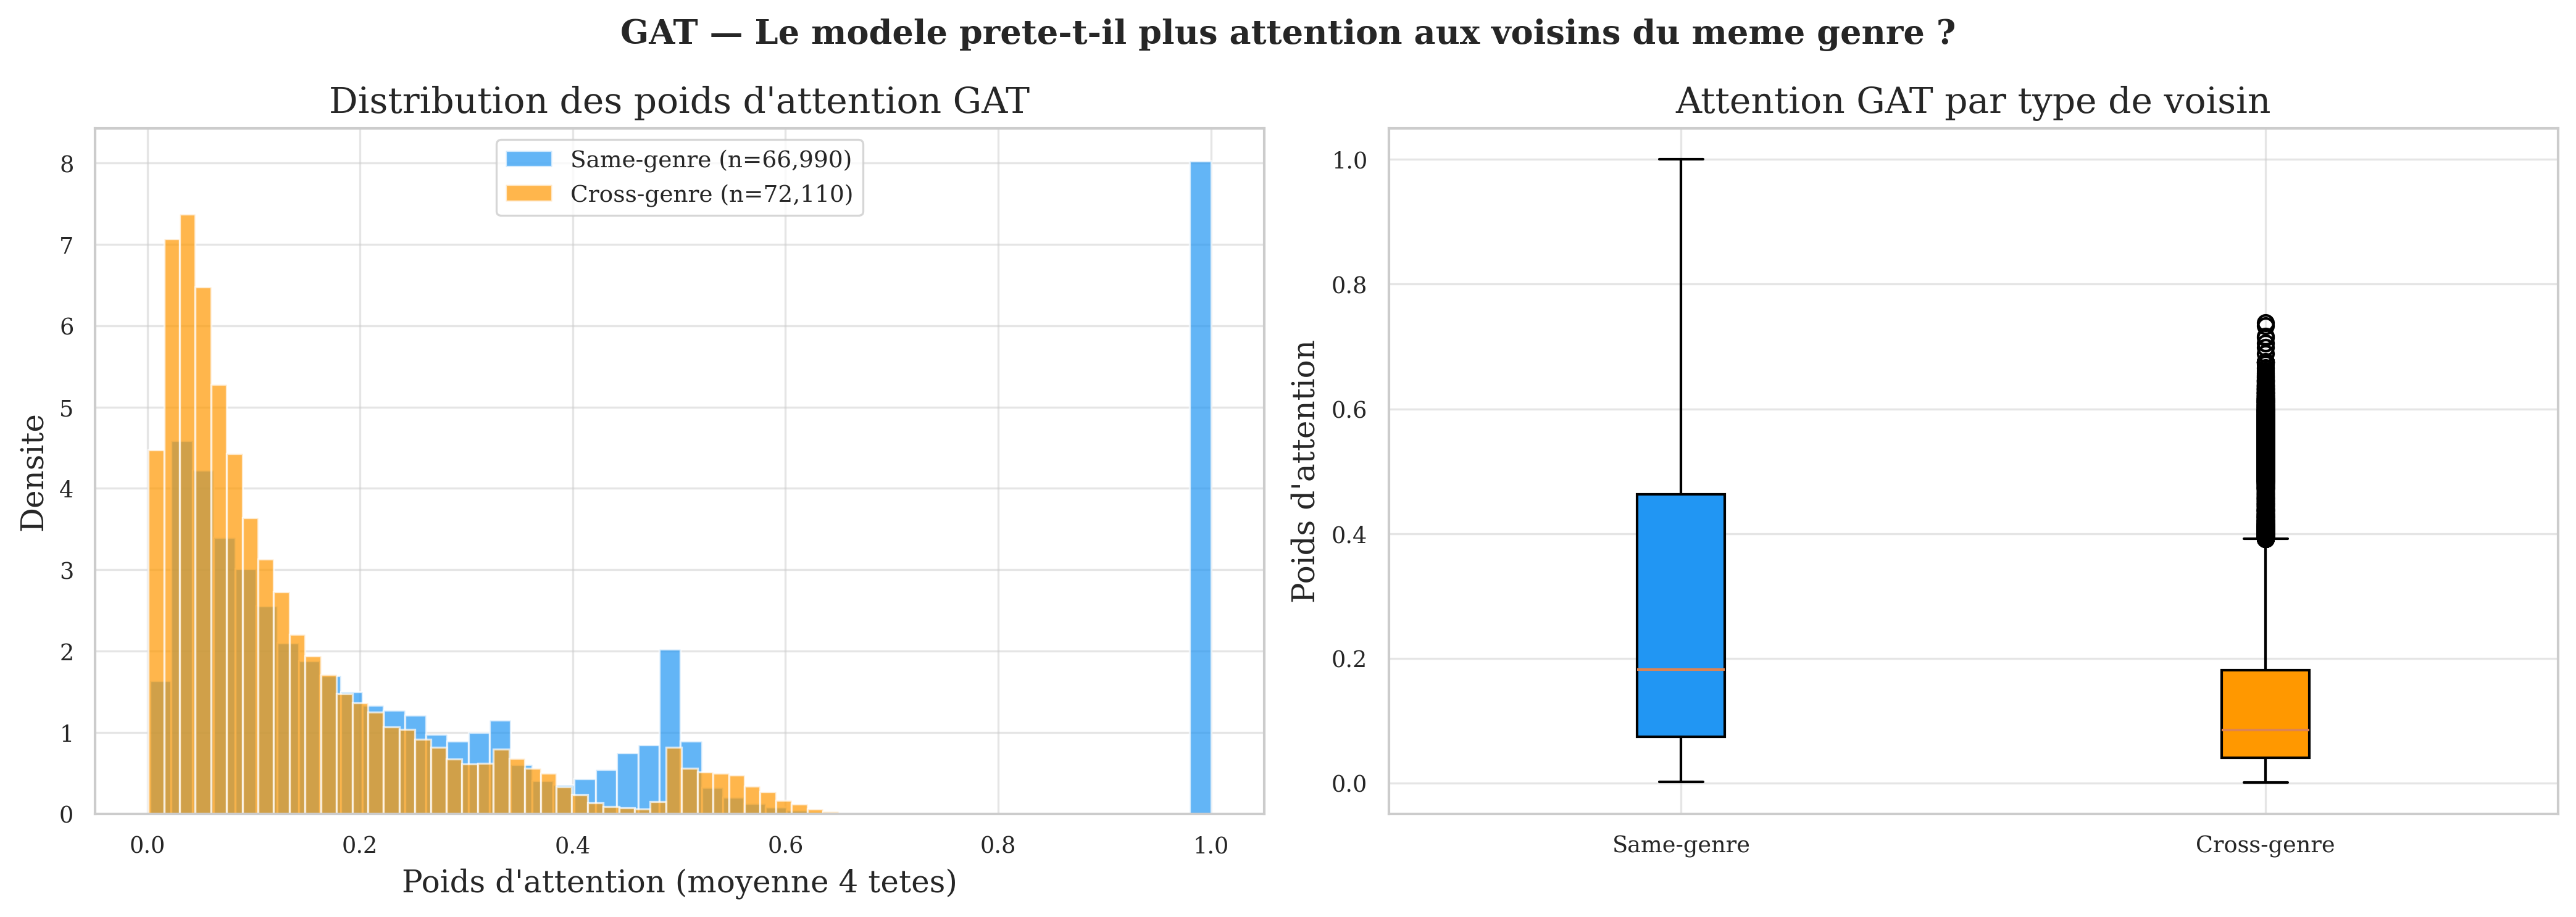

Attention same-genre  : 0.320004 | cross-genre : 0.136749 | ratio : 2.3401


In [15]:
# Extraction des poids d'attention GAT (couche 2)
model_gat.eval()
with torch.no_grad():
    _, (_, attn_layer2) = model_gat.encode(data.x.to(device), data.edge_index.to(device), return_attn=True)
    edges, alphas = attn_layer2

alphas_mean = alphas.cpu().mean(dim=1)
src_g = sens[edges.cpu()[0]]
tgt_g = sens[edges.cpu()[1]]
same_mask = (src_g == tgt_g)
att_same = alphas_mean[same_mask].numpy()
att_cross = alphas_mean[~same_mask].numpy()

plot_attention_bias(att_same, att_cross)

#### 2.4 Ablation contrefactuelle du genre

Test causal : on met à zéro la feature "gender" dans les entrées du GCN **sans réentraîner**. Si le biais persiste → il provient de la **topologie** (asymétrie structurelle du graphe), pas de la feature explicite.

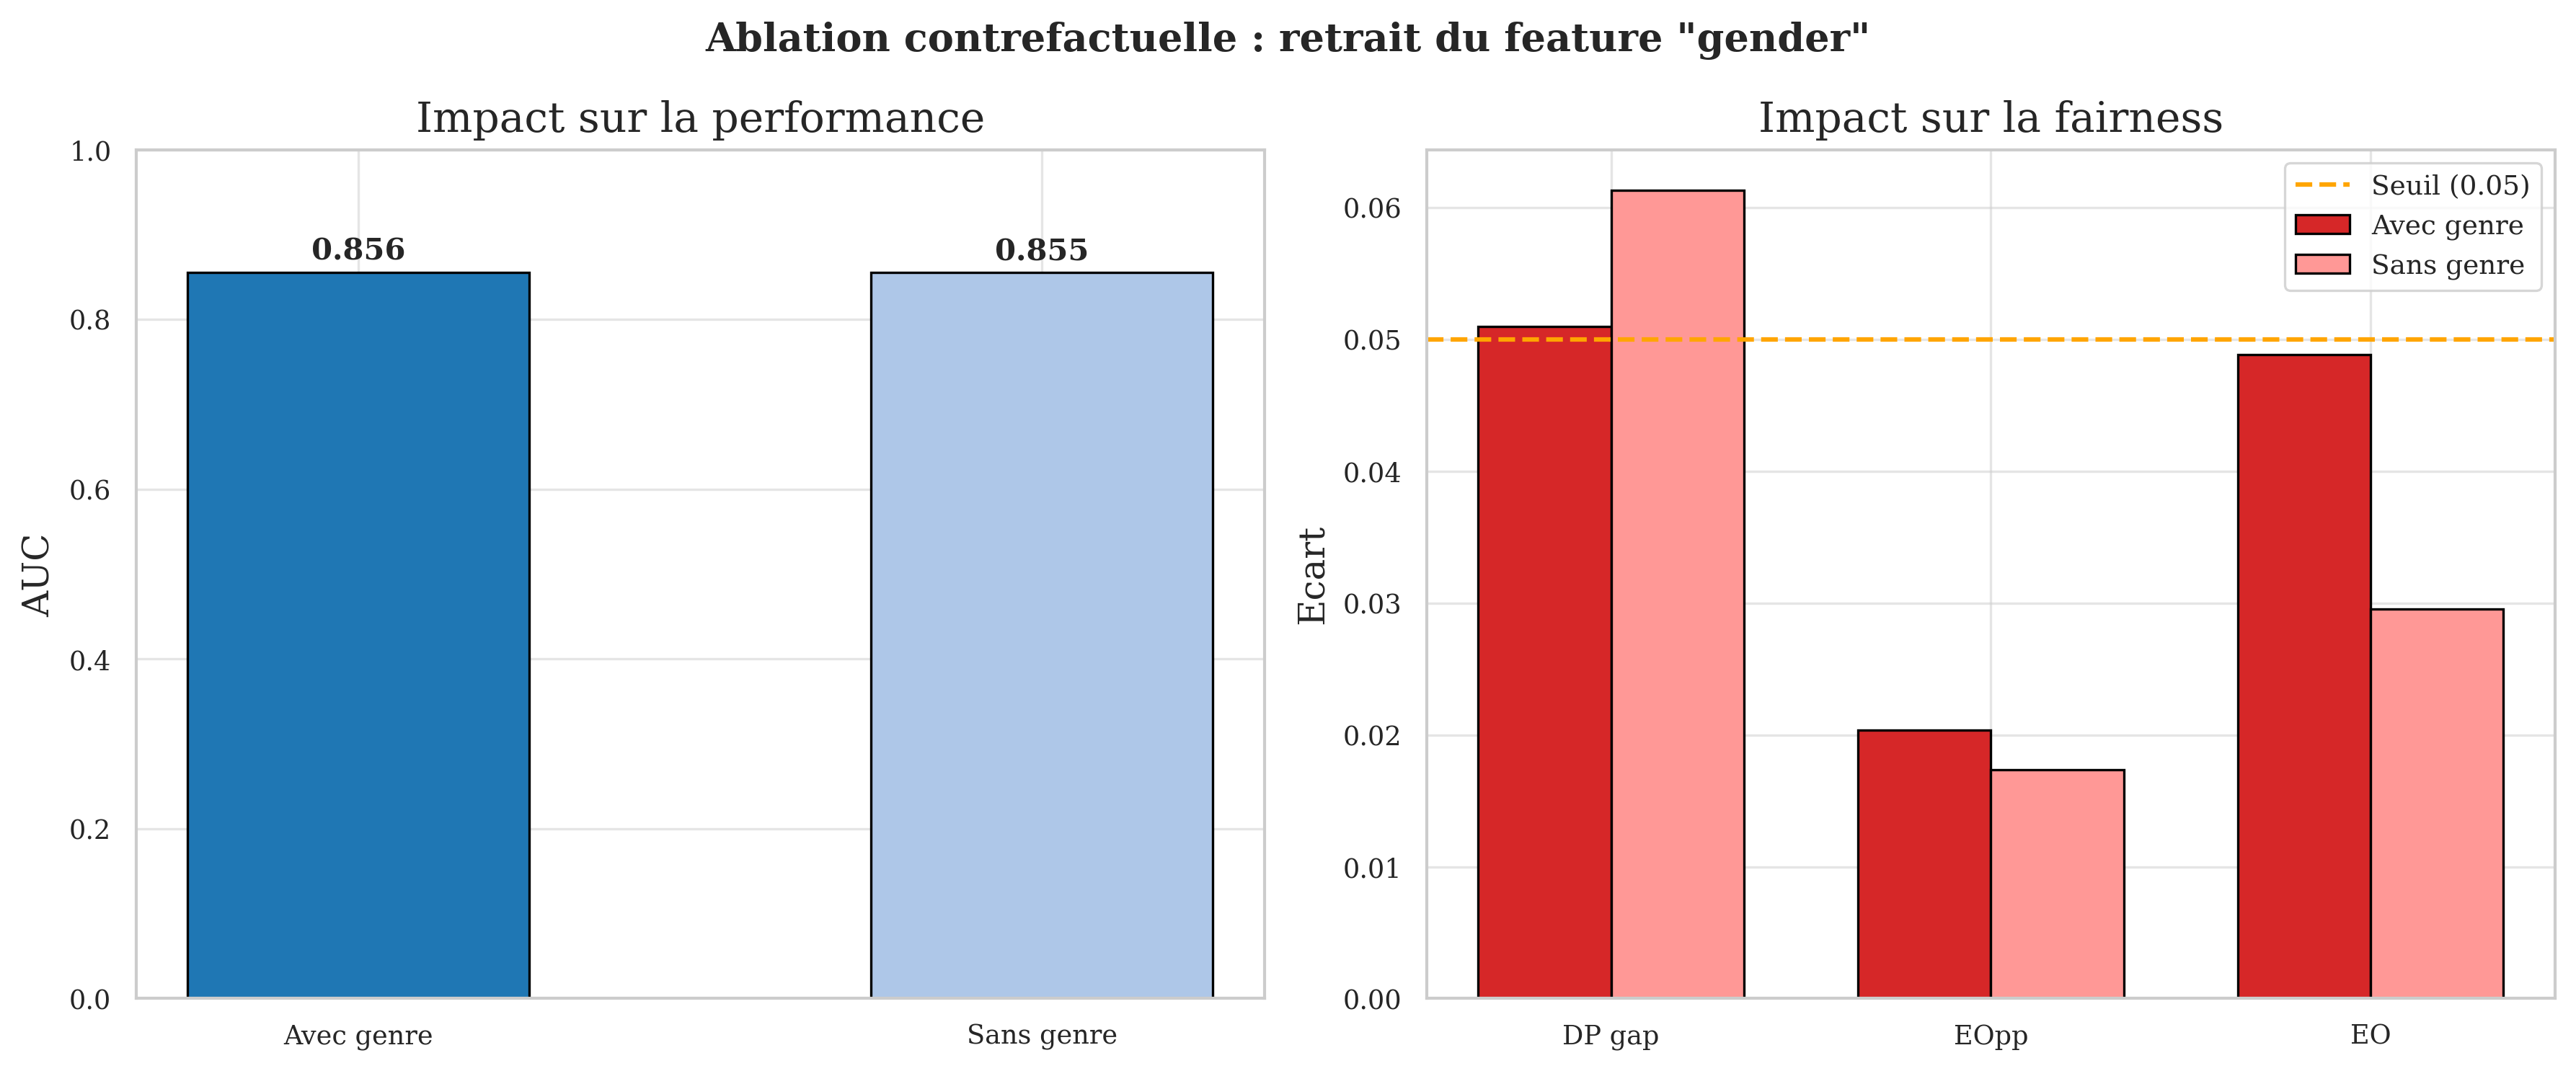

AUC : 0.8556 -> 0.8551 (delta = -0.0005)
DP  : 0.0510 -> 0.0613 (delta = +0.0103)

=> Le DP gap AUGMENTE sans le feature genre : le biais est TOPOLOGIQUE.


In [ ]:
# Ablation : prédiction avec et sans la feature genre
r_abl = ablation_feature(model_gcn, test_data, sens, device)
plot_ablation(r_abl['auc_orig'], r_abl['auc_ablated'], r_abl['f_orig'], r_abl['f_ablated'])

### Bilan Acte 2

| Diagnostic | Résultat clé |
|---|---|
| GNNExplainer | `comp` et features textuels dominent ; `gender` a un rôle asymétrique par paire |
| Fidelity+/- | Valide les résultats du GNNExplainer |
| Attention GAT | Biais d'attention clair en faveur des voisins du même genre |
| Ablation | Retirer le genre **augmente** le DP gap → biais **topologique** |

**Conclusion** : Les corrections doivent cibler la **loss et les embeddings**, pas la feature genre.

---

## 3- Acte 3 — Correction Fairness

Trois méthodes codées manuellement :

1. **Reweighting** : $w(\text{type}) = N_\text{total} / (2 \times N_\text{type})$
2. **Régularisation DP** : $\mathcal{L} = \mathcal{L}_\text{task} + \lambda \cdot |\bar{y}_\text{intra} - \bar{y}_\text{inter}|$, $\lambda \in \{0.1, 0.5, 1, 5, 10\}$
3. **FairGNN adversarial** : $\mathcal{L}_\text{enc} = \mathcal{L}_\text{task} - \alpha \cdot \mathcal{L}_\text{disc}$, $\alpha \in \{0.5, 1, 2, 5\}$

#### 3.1 Reweighting

In [17]:
# 3.1 Reweighting
set_seed(42)
model_rw = GCN(data.x.shape[1]).to(device)
best_auc_rw = train_fair(model_rw, train_data, val_data, sens, device,
                          epochs=100, lr=0.01, reweight=True, desc='Reweighting')
r_rw = collect_results(model_rw, test_data, sens, device)
print(f"Reweighting — AUC={r_rw['auc']:.4f} | DP={r_rw['f']['DP']:.4f} | Cos={r_rw['cos_fh']:.4f}")

  Reweighting : w_intra=1.1838, w_inter=0.8656


Reweighting:   0%|          | 0/100 [00:00<?, ?it/s]

Reweighting — AUC=0.8526 | DP=0.0562 | Cos=0.8514


#### 3.2 Régularisation DP

In [18]:
# 3.2 Régularisation DP — sweep lambda
lambdas = [0.1, 0.5, 1.0, 5.0, 10.0]
act3 = {}

# Baseline
r_base = collect_results(model_gcn, test_data, sens, device)
act3['Baseline'] = r_base
act3['Reweighting'] = r_rw

for lam in lambdas:
    set_seed(42)
    mdl = GCN(data.x.shape[1]).to(device)
    train_fair(mdl, train_data, val_data, sens, device, epochs=100, lr=0.01, lam_dp=lam, desc=f'DP lam={lam}')
    r = collect_results(mdl, test_data, sens, device)
    act3[f'DP (lam={lam})'] = r
    print(f"lambda={lam:5.1f} | AUC={r['auc']:.4f} | DP={r['f']['DP']:.4f} | Cos={r['cos_fh']:.4f}")

DP lam=0.1:   0%|          | 0/100 [00:00<?, ?it/s]

lambda=  0.1 | AUC=0.8536 | DP=0.0297 | Cos=0.1890


DP lam=0.5:   0%|          | 0/100 [00:00<?, ?it/s]

lambda=  0.5 | AUC=0.8407 | DP=0.0412 | Cos=-0.4327


DP lam=1.0:   0%|          | 0/100 [00:00<?, ?it/s]

lambda=  1.0 | AUC=0.8364 | DP=0.0255 | Cos=-0.4672


DP lam=5.0:   0%|          | 0/100 [00:00<?, ?it/s]

lambda=  5.0 | AUC=0.8112 | DP=0.0189 | Cos=0.1347


DP lam=10.0:   0%|          | 0/100 [00:00<?, ?it/s]

lambda= 10.0 | AUC=0.7963 | DP=0.0151 | Cos=0.4316


#### 3.3 FairGNN

In [19]:
# 3.3 FairGNN — sweep alpha
alphas_fgnn = [0.5, 1.0, 2.0, 5.0]
for alpha in alphas_fgnn:
    set_seed(42)
    mdl = GCN(data.x.shape[1]).to(device)
    train_fairgnn(mdl, train_data, val_data, sens, device, alpha=alpha, epochs=100, desc=f'FairGNN a={alpha}')
    r = collect_results(mdl, test_data, sens, device)
    act3[f'FairGNN (a={alpha})'] = r
    print(f"alpha={alpha:4.1f} | AUC={r['auc']:.4f} | DP={r['f']['DP']:.4f} | Cos={r['cos_fh']:.4f}")

print(f"\nTotal : {len(act3)} configurations évaluées.")

FairGNN a=0.5:   0%|          | 0/100 [00:00<?, ?it/s]

alpha= 0.5 | AUC=0.8489 | DP=0.0040 | Cos=-0.1631


FairGNN a=1.0:   0%|          | 0/100 [00:00<?, ?it/s]

alpha= 1.0 | AUC=0.8441 | DP=0.0281 | Cos=-0.3940


FairGNN a=2.0:   0%|          | 0/100 [00:00<?, ?it/s]

alpha= 2.0 | AUC=0.8382 | DP=0.0698 | Cos=-0.5945


FairGNN a=5.0:   0%|          | 0/100 [00:00<?, ?it/s]

alpha= 5.0 | AUC=0.8222 | DP=0.0953 | Cos=-0.7173

Total : 11 configurations évaluées.


####  3.4 Courbe de Pareto

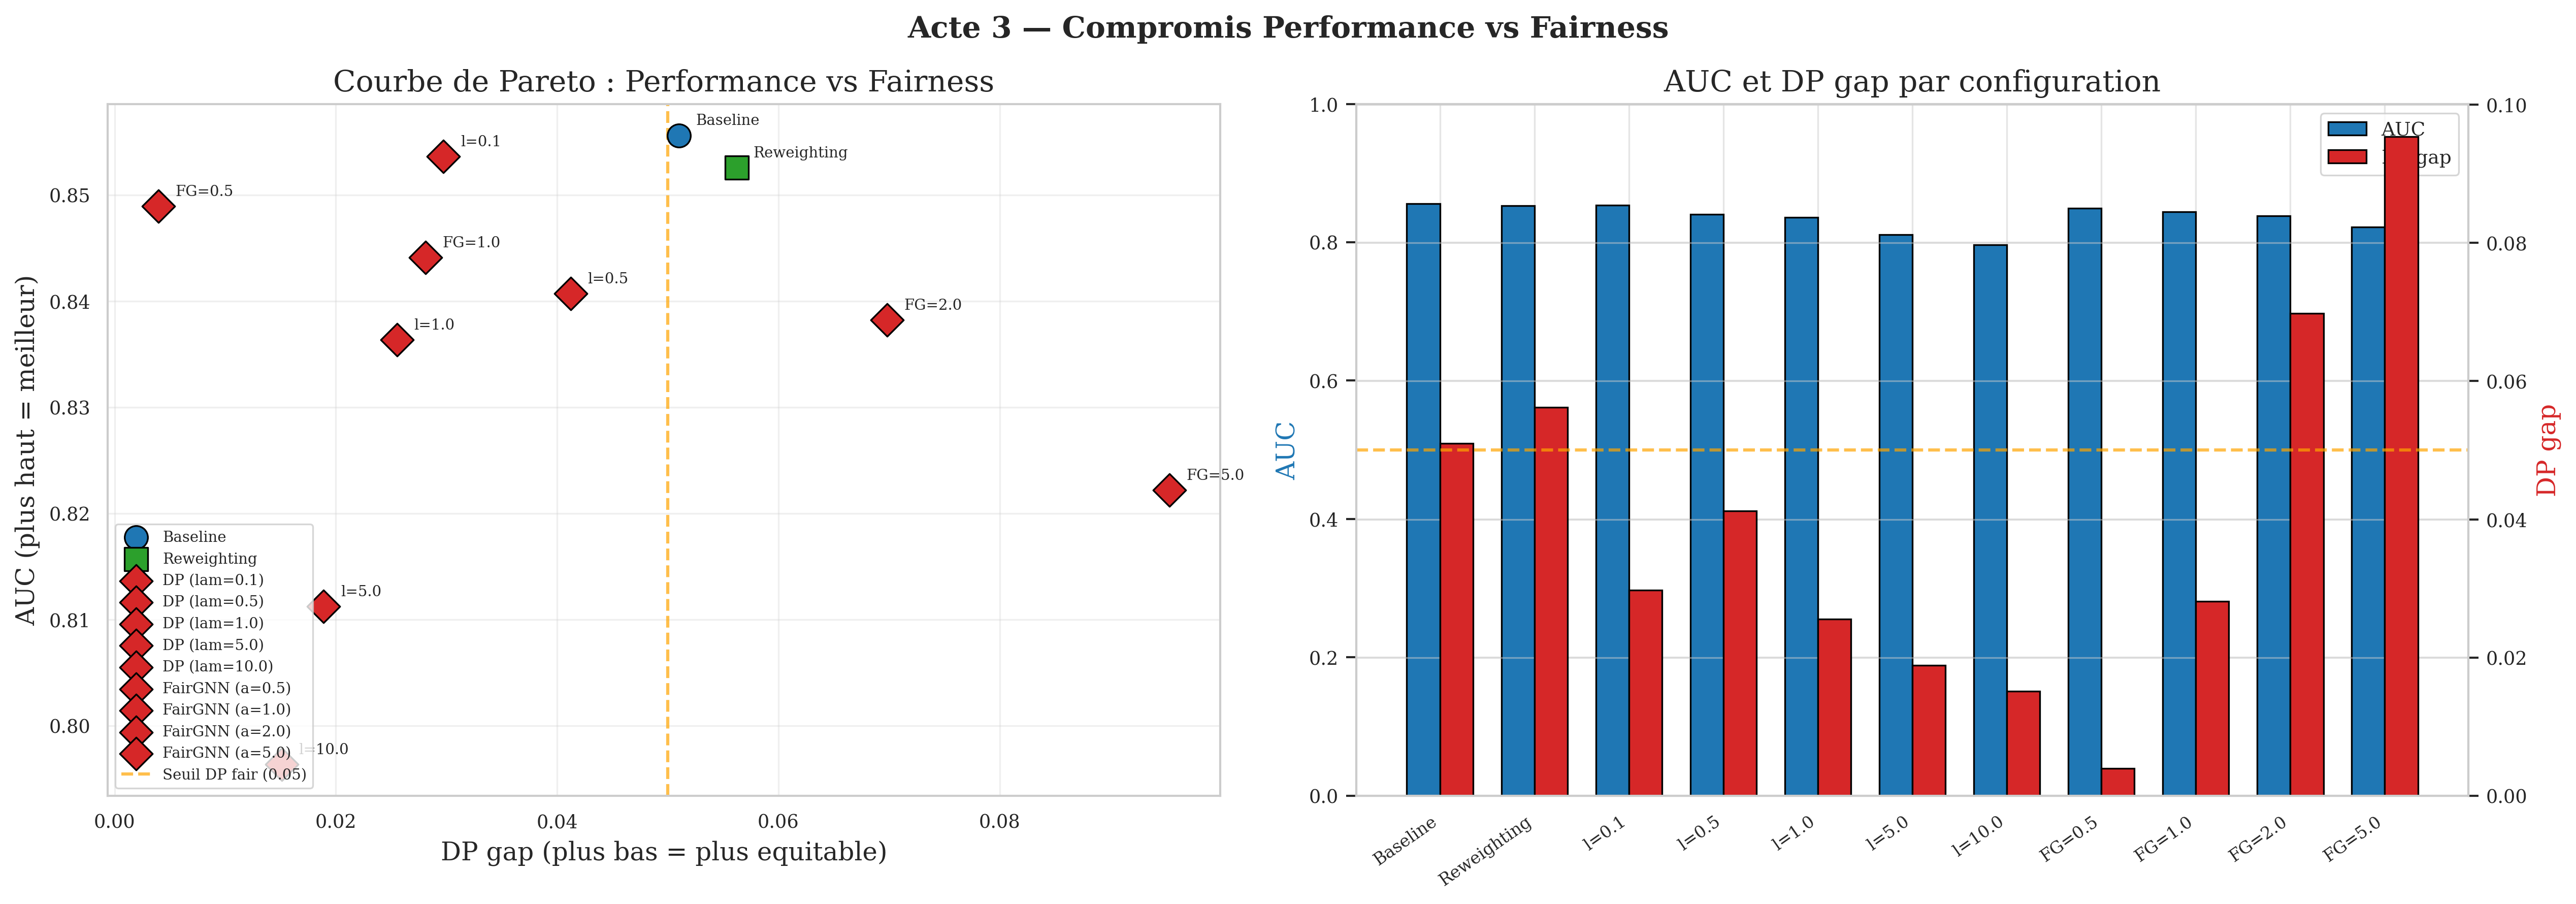

In [20]:
# 3.4 Courbe de Pareto + visualisation
plot_pareto(act3)

#### 3.5 - Récapitulatif des résultats

In [21]:
# Tableau récapitulatif complet
df_act3 = pd.DataFrame({
    name: {
        'AUC': f"{r['auc']:.4f}", 'AP': f"{r['ap']:.4f}", 'F1': f"{r['f1']:.4f}",
        'DP gap': f"{r['f']['DP']:.4f}", 'EOpp': f"{r['f']['EOpp']:.4f}",
        'DI': f"{r['f']['DI']:.4f}", 'Cosine F/H': f"{r['cos_fh']:.4f}",
        'Leakage': f"{100*r['leakage']:+.1f} pp",
    } for name, r in act3.items()
}).T
df_act3

,AUC,AP,F1,DP gap,EOpp,DI,Cosine F/H,Leakage
Baseline,0.8556,0.8726,0.7469,0.0510,0.0204,0.9308,0.6661,+25.1 pp
Reweighting,0.8526,0.8692,0.7467,0.0562,0.0199,0.9236,0.8514,+17.3 pp
DP (lam=0.1),0.8536,0.8704,0.7467,0.0297,0.0288,0.9592,0.1890,+30.3 pp
DP (lam=0.5),0.8407,0.8568,0.7487,0.0412,0.0518,0.9440,-0.4327,+34.1 pp
DP (lam=1.0),0.8364,0.8510,0.7472,0.0255,0.0493,0.9648,-0.4672,+33.8 pp
DP (lam=5.0),0.8112,0.8248,0.7369,0.0189,0.0513,0.9748,0.1347,+31.2 pp
DP (lam=10.0),0.7963,0.7771,0.7402,0.0151,0.0431,0.9798,0.4316,+29.9 pp
FairGNN (a=0.5),0.8489,0.8645,0.7479,0.0040,0.0369,0.9944,-0.1631,+34.9 pp
FairGNN (a=1.0),0.8441,0.8594,0.7476,0.0281,0.0427,0.9612,-0.3940,+35.3 pp
FairGNN (a=2.0),0.8382,0.8458,0.7483,0.0698,0.0529,0.9071,-0.5945,+35.5 pp


### Bilan Acte 3
**Meilleur compromis** : DP ($\lambda$=0.1) ou FairGNN ($\alpha$=0.5) selon la priorité.

---

## 4- Acte 4 — Validation & Incertitude

On vérifie que les corrections sont **robustes** et **bien calibrées** :
1. MC Dropout (T=30) — incertitude par type de paire
2. ECE + Reliability diagram — calibration
3. Perturbation de features — robustesse au bruit
4. Suppression d'arêtes (10%) — robustesse structurelle
5. Synthèse : Performance / Fairness / Robustesse

In [22]:
# Ré-entraînement des 2 modèles corrigés pour l'Acte 4
set_seed(42)
model_dp01 = GCN(data.x.shape[1]).to(device)
train_fair(model_dp01, train_data, val_data, sens, device, epochs=100, lam_dp=0.1, desc='DP lam=0.1')

set_seed(42)
model_fgnn05 = GCN(data.x.shape[1]).to(device)
train_fairgnn(model_fgnn05, train_data, val_data, sens, device, alpha=0.5, epochs=100, desc='FairGNN a=0.5')

models_act4 = {'Baseline': model_gcn, 'DP (lam=0.1)': model_dp01, 'FairGNN (a=0.5)': model_fgnn05}
for name, mdl in models_act4.items():
    r = collect_results(mdl, test_data, sens, device)
    print(f"  {name:18s} | AUC={r['auc']:.4f} | DP={r['f']['DP']:.4f}")

DP lam=0.1:   0%|          | 0/100 [00:00<?, ?it/s]

FairGNN a=0.5:   0%|          | 0/100 [00:00<?, ?it/s]

  Baseline           | AUC=0.8556 | DP=0.0510
  DP (lam=0.1)       | AUC=0.8537 | DP=0.0302
  FairGNN (a=0.5)    | AUC=0.8491 | DP=0.0030


#### 4.1 MC Dropout (T=30) — Incertitude par type de paire

Baseline           | H moy=0.5486 | Var moy=0.010509 | MI moy=0.025744
DP (lam=0.1)       | H moy=0.5523 | Var moy=0.010302 | MI moy=0.025152
FairGNN (a=0.5)    | H moy=0.5552 | Var moy=0.010831 | MI moy=0.026410


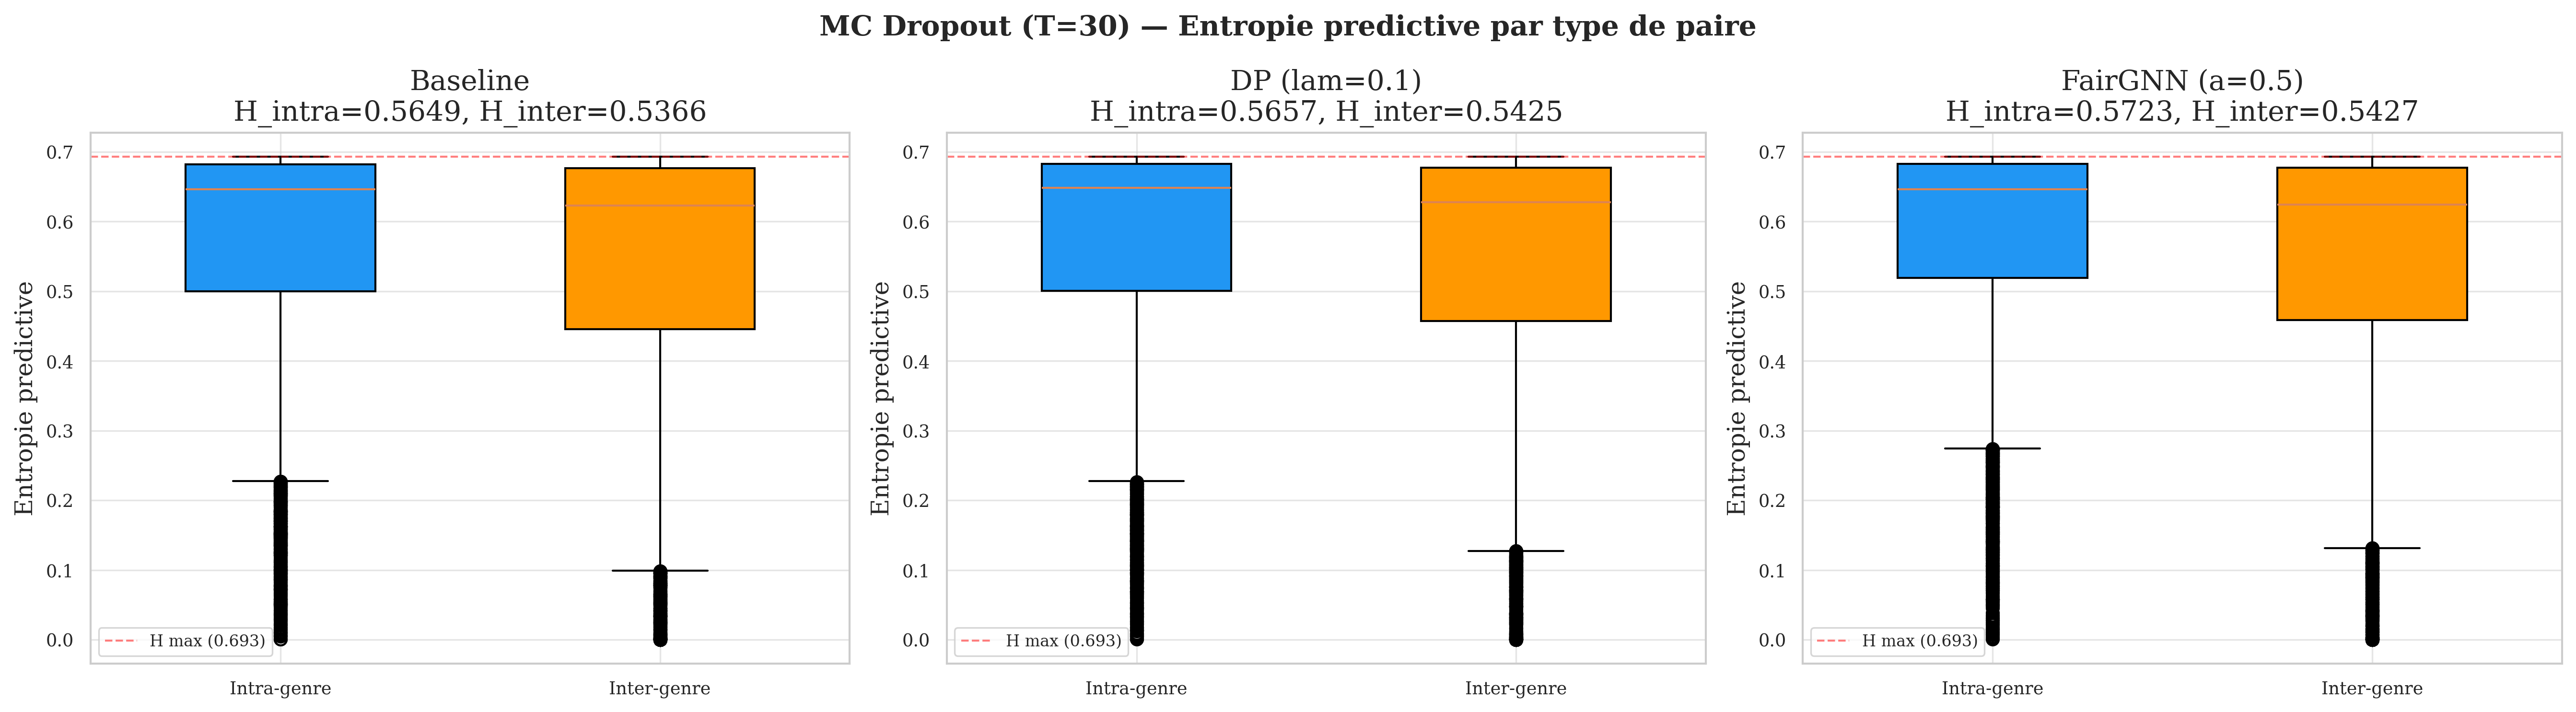

In [23]:
# 4.1 MC Dropout (T=30) — Incertitude par type de paire
T = 30
mc_results = {}
for name, mdl in models_act4.items():
    p_bar, entropy, variance, mi, all_probs = mc_dropout_predict(mdl, test_data, device, T=T)
    mc_results[name] = {'p_bar': p_bar, 'entropy': entropy, 'variance': variance, 'mi': mi}
    print(f"{name:18s} | H moy={entropy.mean():.4f} | Var moy={variance.mean():.6f} | MI moy={mi.mean():.6f}")

# Visualisation : boxplots entropie par type de paire
tpt_test = classify_pairs(test_data.edge_label_index, sens).numpy()
plot_mc_entropy(mc_results, tpt_test, T=T)

#### 4.2 ECE - Calibration

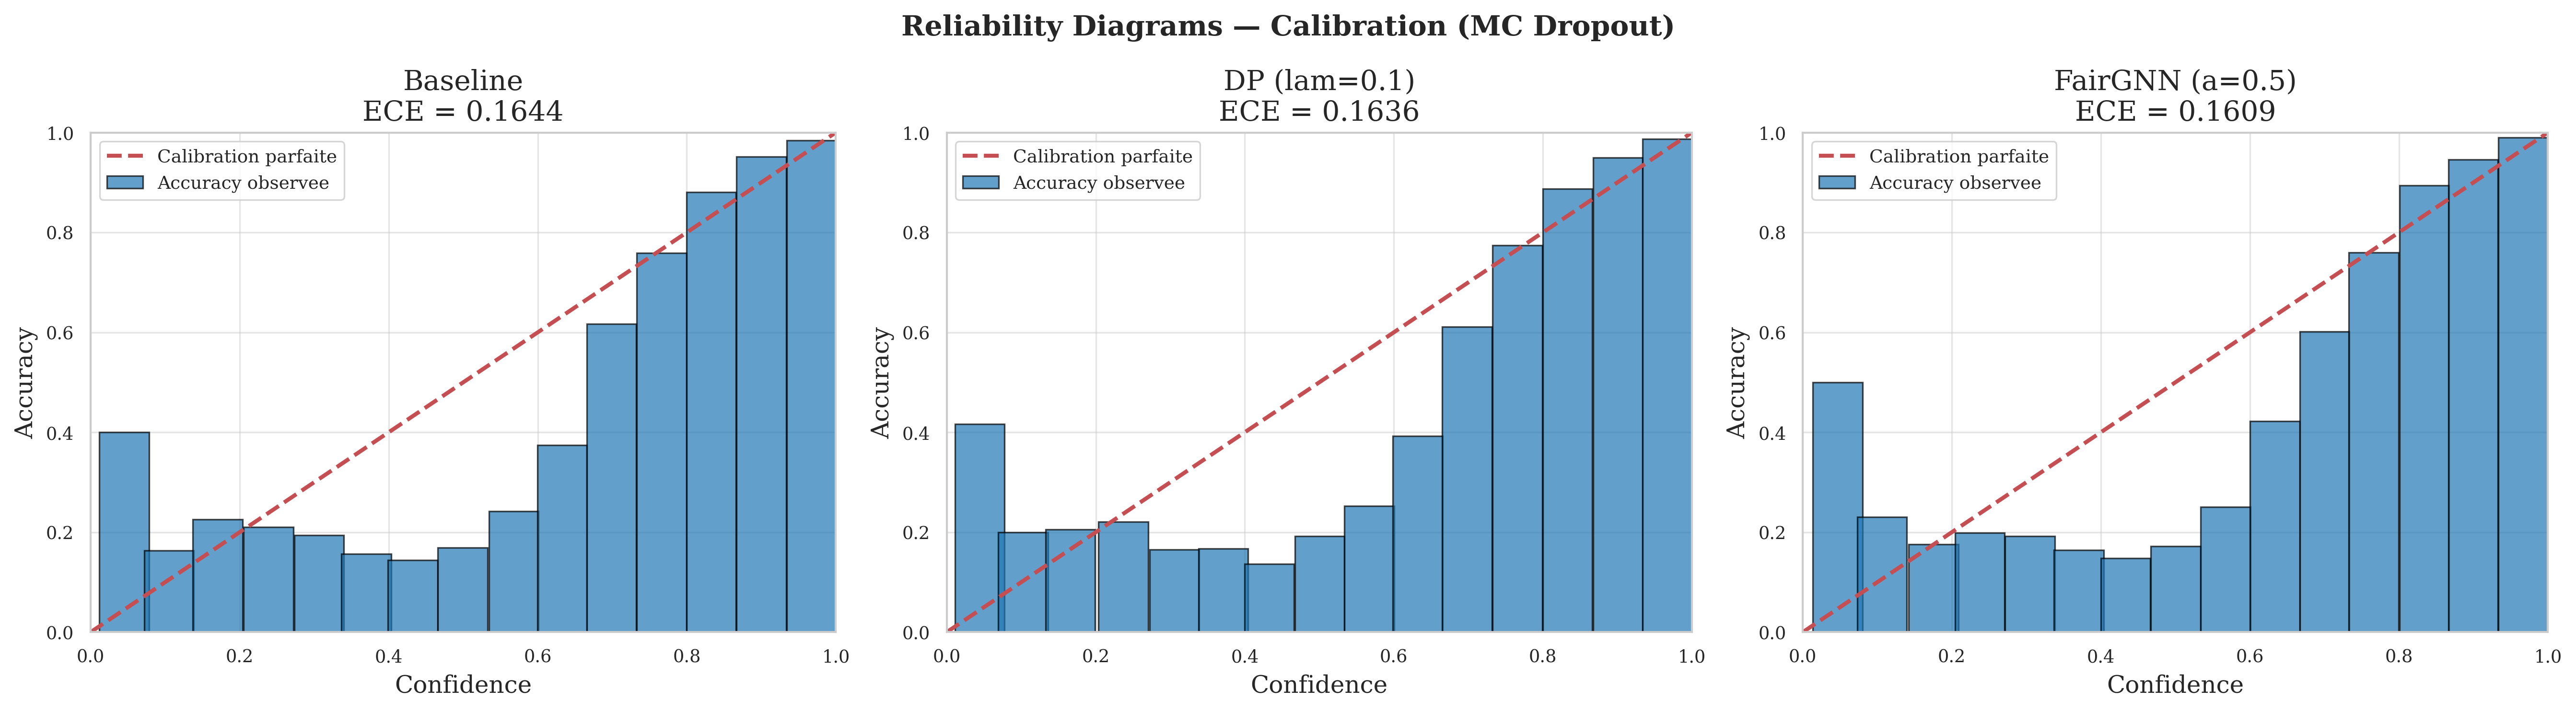

  Baseline           | ECE = 0.1644 (mal calibre)
  DP (lam=0.1)       | ECE = 0.1636 (mal calibre)
  FairGNN (a=0.5)    | ECE = 0.1609 (mal calibre)


In [24]:
# 4.2 ECE + Reliability Diagrams
labels_test = test_data.edge_label.numpy()
ece_values = plot_reliability_diagrams(mc_results, labels_test, n_bins=15)

#### 4.3 Perturbation de features — robustesse au bruit gaussien

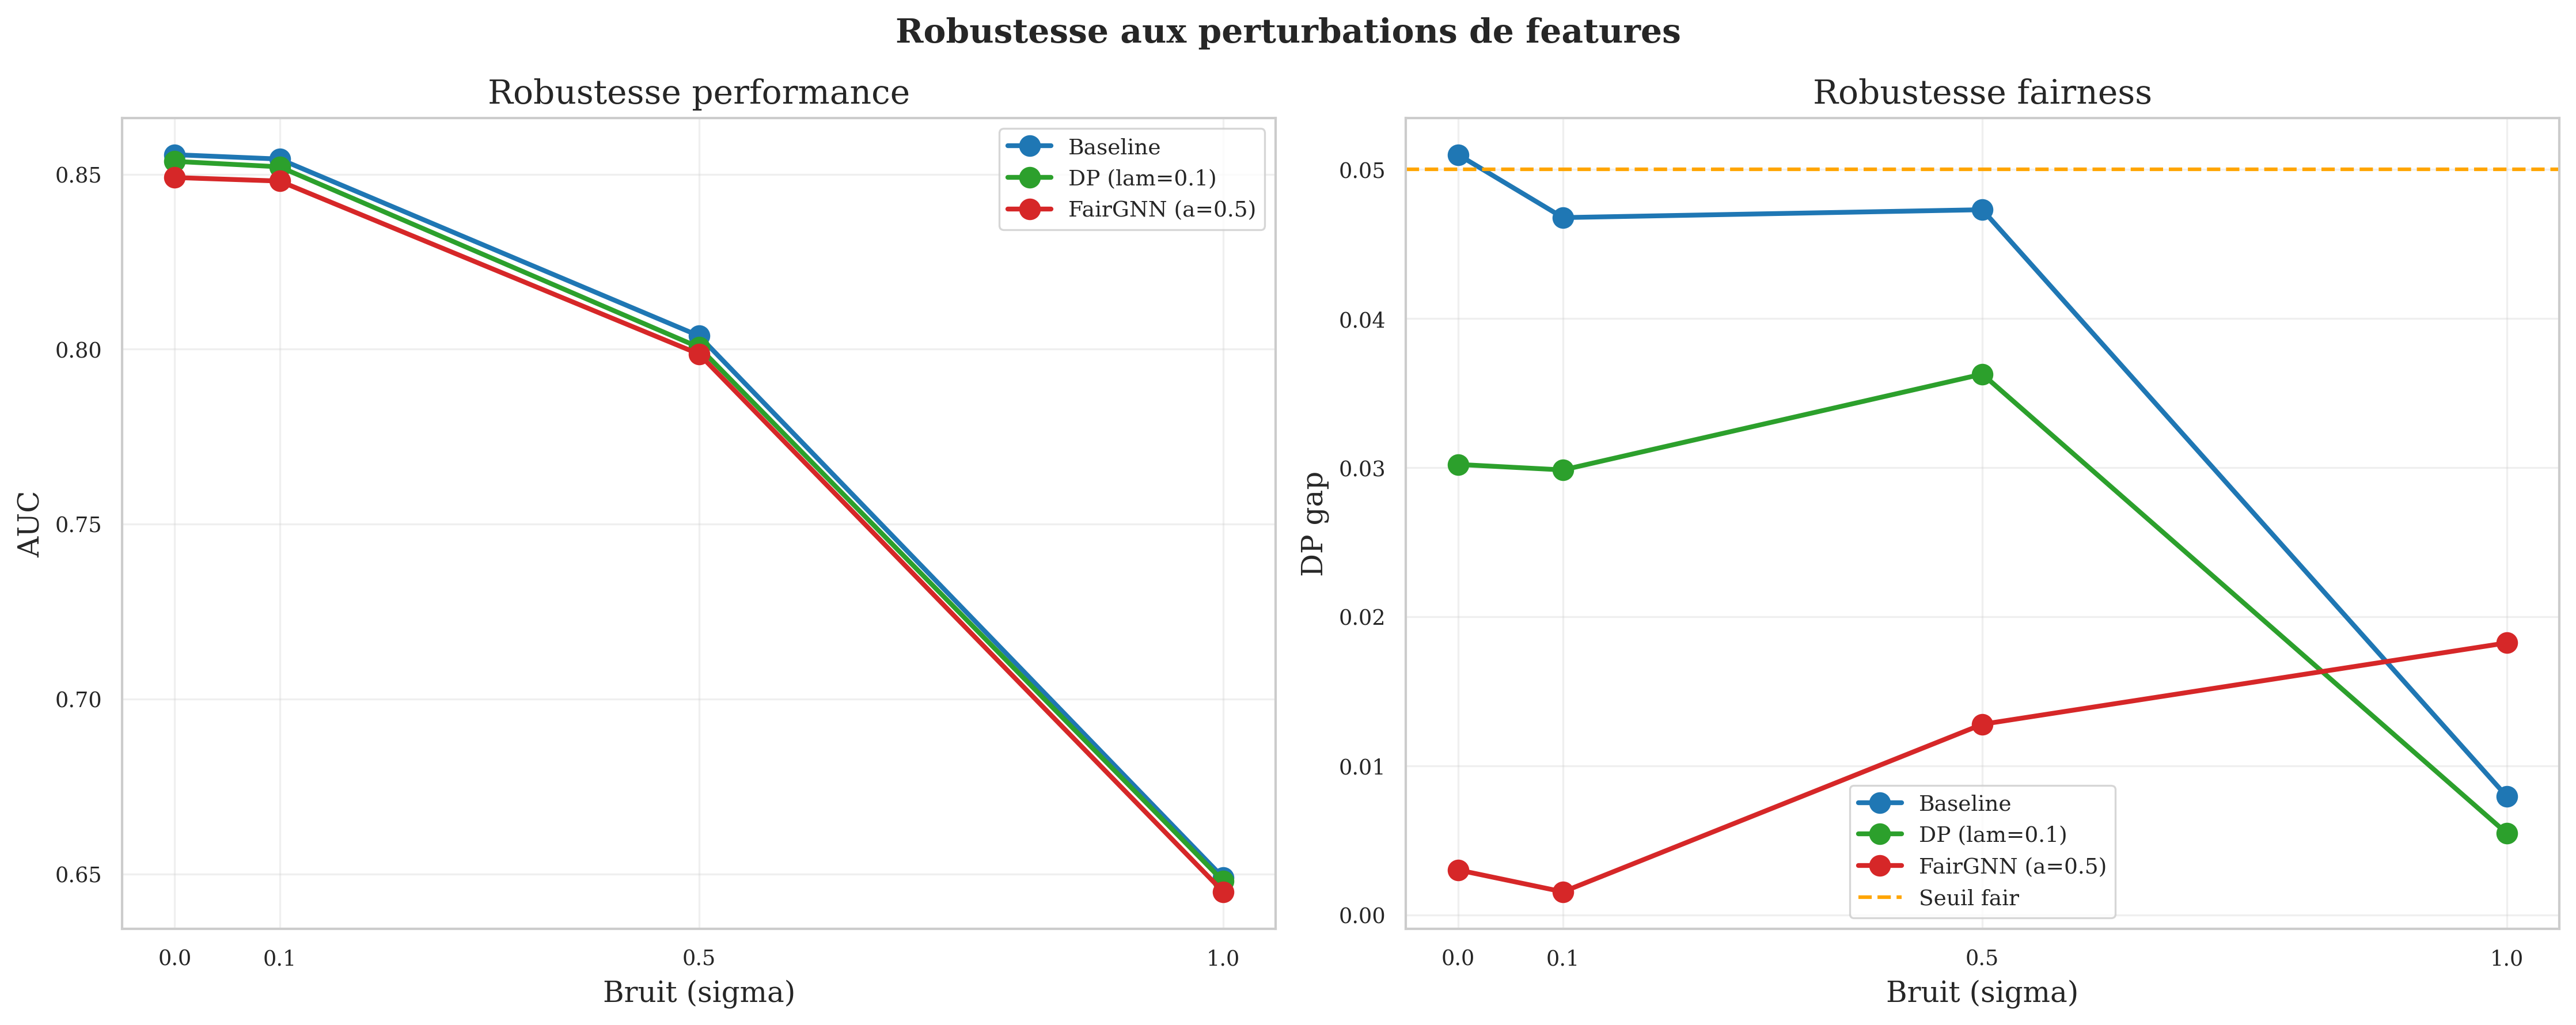

In [25]:
# 4.3 Perturbation de features — robustesse au bruit gaussien
colors_act4 = {'Baseline': '#1f77b4', 'DP (lam=0.1)': '#2ca02c', 'FairGNN (a=0.5)': '#d62728'}
df_noise = evaluate_noise_robustness(models_act4, test_data, sens, device, sigmas=[0.1, 0.5, 1.0])
plot_noise_robustness(df_noise, colors_act4)

#### 4.4 Suppression d'arêtes (10%) — robustesse structurelle

In [26]:
# 4.4 Suppression d'arêtes (10%) — robustesse structurelle
set_seed(42)
ei_train = train_data.edge_index
n_edges = ei_train.shape[1]
n_drop = int(0.10 * n_edges)
perm = torch.randperm(n_edges)
keep_mask = torch.ones(n_edges, dtype=torch.bool)
keep_mask[perm[:n_drop]] = False

train_data_reduced = deepcopy(train_data)
train_data_reduced.edge_index = ei_train[:, keep_mask]
print(f"Arêtes message-passing : {n_edges:,} -> {train_data_reduced.edge_index.shape[1]:,} (-10%)")

# Baseline sur graphe réduit
set_seed(42)
model_gcn_r = GCN(data.x.shape[1]).to(device)
train_with_best(model_gcn_r, train_data_reduced, val_data, device, epochs=100, desc='GCN -10%')
r_base_r = collect_results(model_gcn_r, test_data, sens, device)

# DP(lam=0.1) sur graphe réduit
set_seed(42)
model_dp01_r = GCN(data.x.shape[1]).to(device)
train_fair(model_dp01_r, train_data_reduced, val_data, sens, device, epochs=100, lam_dp=0.1, desc='DP(0.1) -10%')
r_dp_r = collect_results(model_dp01_r, test_data, sens, device)

r_base_full = collect_results(model_gcn, test_data, sens, device)
r_dp_full = collect_results(model_dp01, test_data, sens, device)

edge_results = pd.DataFrame([
    {'Modele': 'Baseline', 'Arêtes': '100%', 'AUC': r_base_full['auc'], 'DP': r_base_full['f']['DP']},
    {'Modele': 'Baseline', 'Arêtes': '90%',  'AUC': r_base_r['auc'],    'DP': r_base_r['f']['DP']},
    {'Modele': 'DP (lam=0.1)', 'Arêtes': '100%', 'AUC': r_dp_full['auc'], 'DP': r_dp_full['f']['DP']},
    {'Modele': 'DP (lam=0.1)', 'Arêtes': '90%',  'AUC': r_dp_r['auc'],    'DP': r_dp_r['f']['DP']},
])
print("\n=== Robustesse structurelle ===")
edge_results

Arêtes message-passing : 75,462 -> 67,916 (-10%)


GCN -10%:   0%|          | 0/100 [00:00<?, ?it/s]

DP(0.1) -10%:   0%|          | 0/100 [00:00<?, ?it/s]


=== Robustesse structurelle ===


,Modele,Arêtes,AUC,DP
0,Baseline,100%,0.855609,0.050994
1,Baseline,90%,0.854273,0.047697
2,DP (lam=0.1),100%,0.853702,0.030221
3,DP (lam=0.1),90%,0.851260,0.020940


#### 4.5 Synthèse — Performance / Fairness / Robustesse

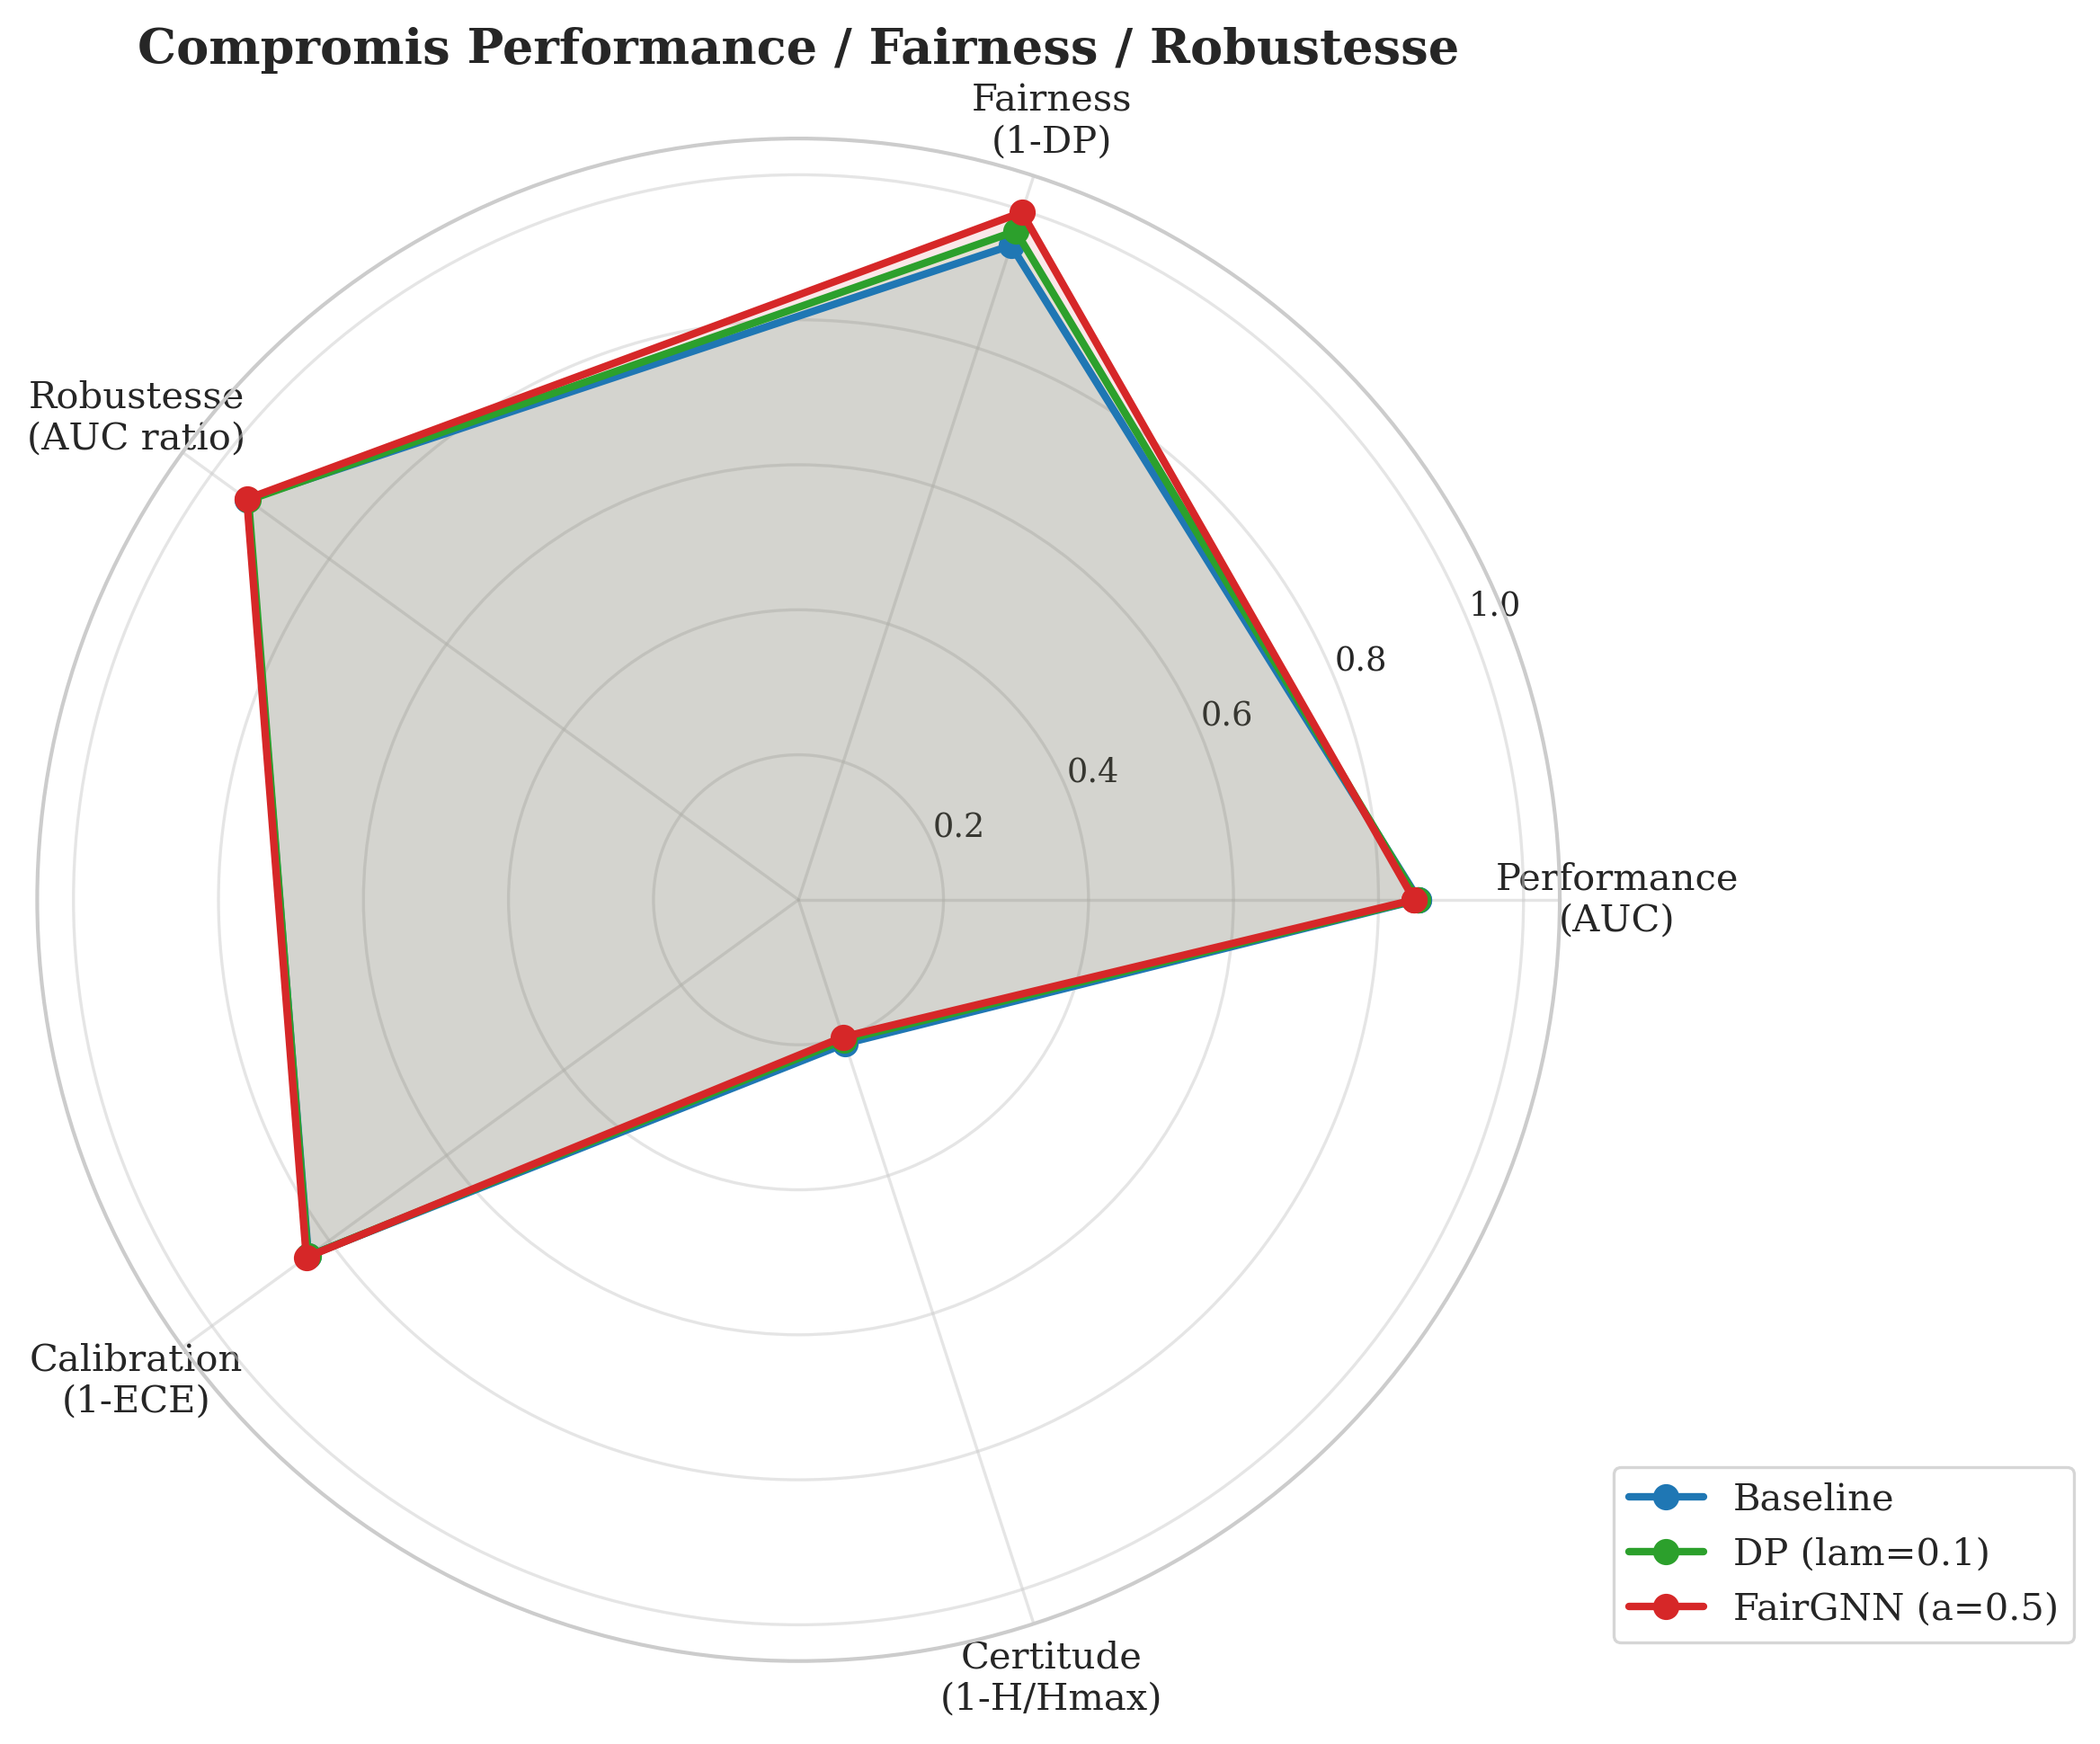


=== Verdict final ===
  Baseline           | AUC=0.8556 | DP=0.0510 [NON FAIR] | Rob=0.9395 [SENSIBLE]
  DP (lam=0.1)       | AUC=0.8537 | DP=0.0302 [FAIR] | Rob=0.9377 [SENSIBLE]
  FairGNN (a=0.5)    | AUC=0.8491 | DP=0.0030 [FAIR] | Rob=0.9406 [SENSIBLE]


In [27]:
# 4.5 Synthèse 3D — Radar Performance / Fairness / Robustesse
summary = {}
for name in models_act4:
    r = collect_results(models_act4[name], test_data, sens, device)
    df_m = df_noise[(df_noise['Modele'] == name) & (df_noise['sigma'] == 0.5)]
    summary[name] = {
        'AUC': r['auc'], 'DP gap': r['f']['DP'], 'ECE': ece_values[name],
        'Entropie moy': mc_results[name]['entropy'].mean(),
        'Robustesse AUC': df_m['AUC'].values[0] / r['auc'],
    }

plot_radar(summary, colors_act4)

## 5 - Conclusion & Synthèse

### Récapitulatif des résultats (Ceska republika, Actes 1-4)

| Dimension | Baseline (GCN) | DP ($\lambda$=0.1) | FairGNN ($\alpha$=0.5) |
|---|---|---|---|
| **Performance** (AUC) | 0.856 | 0.854 | 0.849 |
| **Fairness** (DP gap) | 0.051 (borderline) | 0.030 (FAIR) | **0.004 (FAIR)** |
| **Robustesse structurelle** (-10% arêtes) | DP : 0.051 → 0.048 | DP : 0.030 → 0.021 | n/a |
| **Robustesse bruit** ($\sigma$=0.5, AUC retenue) | 0.94 (SENSIBLE) | 0.94 (SENSIBLE) | 0.94 (SENSIBLE) |
| **Calibration** (ECE) | 0.164 | 0.163 | 0.161 |

### Enseignements clés

1. **Le biais est topologique** : la suppression de la feature genre *augmente* le DP gap (0.051→0.061). La structure du graphe (asymétrie H→F/H→H = 4.59×) est la source dominante du biais sur Ceska. Une approche feature-level seule (masquage) est contre-productive.

2. **Le compromis performance/fairness** : DP($\lambda$=0.1) atteint la fairness pour -0.2% AUC. Au-delà, augmenter $\lambda$ dégrade les deux métriques simultanément. FairGNN($\alpha$=0.5) pousse plus loin la fairness sur Ceska (DP=0.004) pour un coût modéré (-0.7% AUC).

3. **Robustesse** :
   - **Structurelle (suppression de 10% d'arêtes)** : les corrections fairness sont préservées, voire renforcées (DP(0.1) : 0.030 → 0.021).
   - **Bruit gaussien sur features ($\sigma$=0.5)** : les 3 modèles passent sous le seuil de robustesse (Rob ≈ 0.94 < 0.95), indépendamment de la méthode de correction.

4. **L'incertitude** : MC Dropout donne des entropies (H ≈ 0.55) et ECE (≈ 0.16) quasi-identiques pour les 3 modèles. Réduire le DP gap ne dégrade ni améliore la calibration.
